# EntityGuard — Student 3 Notebook
### Statistics, Evaluation, Machine Learning, Error Analysis & Application

**Project:** EntityGuard — Scalable Entity Resolution on the DBLP–Scholar benchmark
**My role (Student 3):** threshold evaluation · precision / recall / F1 · Logistic Regression & Decision Tree · error analysis · scalability results · human-review interface · dashboard

---

**How to run this notebook in Google Colab**

1. `Runtime → Change runtime type → CPU` (no GPU needed).
2. Put `DBLP-Scholar.zip` in your Google Drive in a folder called **`EntityGuard`** (i.e. `My Drive/EntityGuard/DBLP-Scholar.zip`).
   If it is not there, the notebook will ask you to upload it.
3. `Runtime → Run all`. (The manual-review loop in Section 20 only runs if you set `RUN_MANUAL_REVIEW = True`.) The full run takes roughly **5–10 minutes** on free Colab.
4. All results (CSV tables, plots, SQLite database, review decisions) are saved to `My Drive/EntityGuard/outputs/`, so they survive a Colab disconnect.
5. The last sections start the **web app** (review interface + dashboard). Click the public `gradio.live` link it prints.

**About my teammates' code.** This notebook imports the team's modules from the repo's `src/` package:
- **Student 1** — `src/normalize.py`, `src/similarity.py`: all normalization and the reference similarity functions. For speed, `src/matching/features.py` computes the *same* numbers vectorized; Section 5 and `tests/test_features.py` check that they are equal.
- **Student 2** — blocking is still the 🔁 *reference version* in Section 9 until `src/blocking/` exists.
- **Student 3 (me)** — `src/evaluation/`, `src/matching/`, `src/ml/`.

In Colab the repo is cloned automatically (Section 1) if `src/` is not in the Drive folder.

**Important rule from the problem statement:** the `GOLD_MATCH` table is used **only for evaluation** — never to generate predictions. Weights and thresholds are tuned on a *validation* split and reported on a *test* split that is never used for tuning.

## 1. Setup

In [1]:
!pip -q install rapidfuzz gradio

In [2]:
import os, sys, time, re, json, math, random, sqlite3, zipfile, glob, shutil, string, unicodedata, itertools, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein as RFLevenshtein

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
random.seed(SEED); np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/EntityGuard"
else:
    # Local run: EG_BASE if set, otherwise the repo root (the folder holding data/).
    # Works whether Jupyter was started in the repo root or in experiments/.
    _cwd = os.path.abspath(os.getcwd())
    _repo = next((p for p in (_cwd, os.path.dirname(_cwd)) if os.path.isdir(os.path.join(p, "data"))), _cwd)
    BASE = os.environ.get("EG_BASE", _repo)

DATA_DIR = f"{BASE}/data"
OUT_DIR = f"{BASE}/outputs"
for d in (BASE, DATA_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

# SQLite works best on the local Colab disk; we copy it to Drive at the end.
DB_PATH = "/content/entityguard.db" if IN_COLAB else f"{BASE}/entityguard.db"
REVIEW_CSV = f"{OUT_DIR}/human_reviews.csv"   # review decisions are also appended here (persistent)

# The project code lives in the repo's src/ package. Locally BASE is the repo root.
# In Colab: use src/ from the Drive folder if it is there, otherwise clone the repo to /content.
REPO_URL = "https://github.com/shivamkumar516/EntityGuard.git"
if os.path.isdir(f"{BASE}/src"):
    REPO_DIR = BASE
else:
    import subprocess
    REPO_DIR = "/content/EntityGuard"
    if os.path.isdir(REPO_DIR):
        subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

def save_fig(fig, name):
    path = f"{OUT_DIR}/{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    return path

print("Running in Colab:", IN_COLAB)
print("Project folder  :", BASE)
print("Code (src/) from:", REPO_DIR)

Running in Colab: False
Project folder  : c:\Users\Acer\Documents\GitHub\EntityGuard
Code (src/) from: c:\Users\Acer\Documents\GitHub\EntityGuard


## 2. Get the dataset

The notebook looks for the three CSV files in `EntityGuard/data/` (Colab: `MyDrive/EntityGuard`, locally: the repo root). The DBLP file may be called `DBLP.csv` (as in the repo) or `DBLP1.csv` (as in the original zip). If they are missing it unzips `DBLP-Scholar.zip` from the `EntityGuard` folder (or from `/content`), and if that is missing too it opens an upload dialog.

In [3]:
DBLP_NAMES = ["DBLP.csv", "DBLP1.csv"]          # repo name, original zip name
OTHER_FILES = ["Scholar.csv", "DBLP-Scholar_perfectMapping.csv"]
FILES = DBLP_NAMES + OTHER_FILES

def dblp_name():
    return next((n for n in DBLP_NAMES if os.path.exists(f"{DATA_DIR}/{n}")), None)

def have_files():
    return dblp_name() is not None and all(os.path.exists(f"{DATA_DIR}/{f}") for f in OTHER_FILES)

def extract_zip(zpath):
    with zipfile.ZipFile(zpath) as z:
        z.extractall(DATA_DIR)
    # files may sit inside a sub-folder of the zip -> move them up
    for root, _, names in os.walk(DATA_DIR):
        for n in names:
            if n in FILES and root != DATA_DIR:
                shutil.move(os.path.join(root, n), os.path.join(DATA_DIR, n))

if not have_files():
    zips = [p for p in glob.glob(f"{BASE}/*.zip") + glob.glob("/content/*.zip") if "scholar" in p.lower()]
    if not zips and IN_COLAB:
        from google.colab import files
        print("Please upload DBLP-Scholar.zip")
        uploaded = files.upload()
        for name, content in uploaded.items():
            with open(f"{BASE}/{name}", "wb") as f:
                f.write(content)
            zips.append(f"{BASE}/{name}")
    for z in zips:
        extract_zip(z)

assert have_files(), f"Dataset not found. Put DBLP-Scholar.zip into {BASE}"
DBLP_FILE = f"{DATA_DIR}/{dblp_name()}"
print("Dataset files:", os.listdir(DATA_DIR))

Dataset files: ['DBLP-Scholar_perfectMapping.csv', 'DBLP.csv', 'Scholar.csv']


## 3. Load data & initial dataset analysis (Section 10 of the problem statement)

⚠️ The two files use **different text encodings**: `DBLP.csv` (`DBLP1.csv` in the zip) is Latin-1 and `Scholar.csv` is UTF-8 with a BOM. Reading both the same way breaks names such as *Wäsch*.

In [4]:
dblp = pd.read_csv(DBLP_FILE, encoding="latin-1")
scholar = pd.read_csv(f"{DATA_DIR}/Scholar.csv", encoding="utf-8-sig")
gold_df = pd.read_csv(f"{DATA_DIR}/DBLP-Scholar_perfectMapping.csv").rename(
    columns={"idDBLP": "dblp_id", "idScholar": "scholar_id"})

for df in (dblp, scholar):
    df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
    for c in ("title", "authors", "venue"):
        df[c] = df[c].where(df[c].notna() & (df[c].astype(str).str.strip() != ""), None)

N_D, N_S = len(dblp), len(scholar)
P_ALL = N_D * N_S
GOLD = set(zip(gold_df.dblp_id, gold_df.scholar_id))
print(f"DBLP records    : {N_D:,}")
print(f"Scholar records : {N_S:,}")
print(f"Gold matches    : {len(GOLD):,}")
print(f"Cartesian pairs : {P_ALL:,}")
dblp.head(3)

DBLP records    : 2,616
Scholar records : 64,263
Gold matches    : 5,347
Cartesian pairs : 168,112,008


,id,title,authors,venue,year
0,conf/vldb/RusinkiewiczKTWM95,Towards a Cooperative Transaction Model - The Cooperative Activity Model,"M Rusinkiewicz, W Klas, T Tesch, J Wäsch, P Muth",VLDB,1995
1,journals/sigmod/EisenbergM02,SQL/XML is Making Good Progress,"A Eisenberg, J Melton",SIGMOD Record,2002
2,conf/vldb/AmmannJR95,Using Formal Methods to Reason about Semantics-Based Decompositions of Trans...,"P Ammann, S Jajodia, I Ray",VLDB,1995


In [5]:
def profile(df, name):
    t = df["title"].fillna("")
    a = df["authors"].fillna("")
    return {
        "source": name,
        "records": len(df),
        "missing title": int(df.title.isna().sum()),
        "missing authors": int(df.authors.isna().sum()),
        "missing venue": int(df.venue.isna().sum()),
        "missing year": int(df.year.isna().sum()),
        "missing year %": round(100 * df.year.isna().mean(), 1),
        "unique years": int(df.year.nunique()),
        "year range": f"{df.year.min()}–{df.year.max()}",
        "avg title length (chars)": round(t.str.len().mean(), 1),
        "avg title length (words)": round(t.str.split().str.len().mean(), 1),
        "avg authors per record": round(a[a != ""].str.split(",").str.len().mean(), 2),
        "duplicate IDs": int(df.id.duplicated().sum()),
    }

stats_df = pd.DataFrame([profile(dblp, "DBLP"), profile(scholar, "Scholar")]).set_index("source").T
stats_df.to_csv(f"{OUT_DIR}/dataset_statistics.csv")
stats_df

source,DBLP,Scholar
records,2616,64263
missing title,0,0
missing authors,218,1
missing venue,211,14997
missing year,0,34790
missing year %,0.0,54.1
unique years,10,127
year range,1994–2003,11–2730
avg title length (chars),56.4,60.6
avg title length (words),7.5,8.1


In [6]:
def punct_freq(series):
    c = Counter(ch for s in series.dropna() for ch in s if ch in string.punctuation)
    return c

pf = pd.DataFrame({"DBLP": punct_freq(dblp.title), "Scholar": punct_freq(scholar.title)}).fillna(0).astype(int)
pf["DBLP per 100 titles"] = (100 * pf.DBLP / N_D).round(1)
pf["Scholar per 100 titles"] = (100 * pf.Scholar / N_S).round(1)
punct_df = pf.sort_values("Scholar", ascending=False).head(12)
punct_df.to_csv(f"{OUT_DIR}/punctuation_frequency.csv")
print("Punctuation in titles")
punct_df

Punctuation in titles


,DBLP,Scholar,DBLP per 100 titles,Scholar per 100 titles
-,994,19821,38.0,30.8
:,692,14142,26.5,22.0
",",241,13894,9.2,21.6
.,27,11312,1.0,17.6
?,50,8776,1.9,13.7
(,98,3091,3.7,4.8
),98,2872,3.7,4.5
;,2,1885,0.1,2.9
&,6,1505,0.2,2.3
',134,1482,5.1,2.3


In [7]:
venues_df = pd.concat([
    dblp.venue.value_counts().head(10).rename_axis("DBLP venue").reset_index(name="DBLP count"),
    scholar.venue.value_counts().head(10).rename_axis("Scholar venue").reset_index(name="Scholar count")], axis=1)
venues_df.to_csv(f"{OUT_DIR}/common_venues.csv", index=False)
venues_df

,DBLP venue,DBLP count,Scholar venue,Scholar count
0,VLDB,861.0,"LECTURE NOTES IN COMPUTER SCIENCE,",964
1,SIGMOD Conference,771.0,"Cochrane Database Syst Rev,",910
2,SIGMOD Record,449.0,"New Directions for Higher Education,",894
3,VLDB J.,191.0,"Phil. Mag,",832
4,ACM Trans. Database Syst.,132.0,"Computer Networks,",796
5,ecord,1.0,"BT Technology Journal,",751
6,NaN,NaN,"VLDB,",741
7,NaN,NaN,"SIGMOD Record,",738
8,NaN,NaN,"Information and Software Technology,",690
9,NaN,NaN,"ACM Transactions on Database Systems,",685


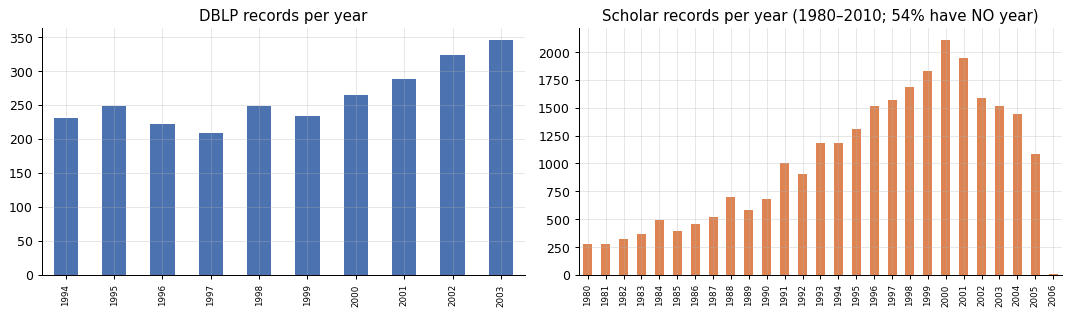

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dblp.year.value_counts().sort_index().plot(kind="bar", ax=ax[0], color="#4C72B0")
ax[0].set_title("DBLP records per year"); ax[0].set_xlabel("")
sy = scholar.year.dropna()
sy[(sy >= 1980) & (sy <= 2010)].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="#DD8452")
ax[1].set_title(f"Scholar records per year (1980–2010; {scholar.year.isna().mean():.0%} have NO year)")
ax[1].set_xlabel("")
for a in ax:
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); save_fig(fig, "year_distribution"); plt.show()

### 3.1 Inspecting the gold mapping

Key facts that shape the evaluation design:
- the mapping is **many-to-many** — one DBLP paper can match several Scholar records (Scholar often has duplicates of the same paper), so we must **not** force a 1-to-1 assignment;
- we check how often the gold pairs agree on year / exact title, which tells us how much weight those attributes deserve.

In [9]:
dd = dblp.set_index("id"); ss = scholar.set_index("id")
g = gold_df.copy()
g["d_year"] = g.dblp_id.map(dd.year); g["s_year"] = g.scholar_id.map(ss.year)
per_dblp = g.groupby("dblp_id").size()

gold_facts = {
    "gold pairs": len(g),
    "distinct DBLP ids in gold": g.dblp_id.nunique(),
    "distinct Scholar ids in gold": g.scholar_id.nunique(),
    "DBLP records with >1 Scholar match": int((per_dblp > 1).sum()),
    "max Scholar matches for one DBLP record": int(per_dblp.max()),
    "DBLP records with NO gold match": N_D - g.dblp_id.nunique(),
    "gold pairs: same year": int((g.d_year == g.s_year).sum()),
    "gold pairs: year differs": int(((g.d_year != g.s_year) & g.s_year.notna()).sum()),
    "gold pairs: Scholar year missing": int(g.s_year.isna().sum()),
}
pd.Series(gold_facts, name="value").to_frame()

,value
gold pairs,5347
distinct DBLP ids in gold,2408
distinct Scholar ids in gold,5218
DBLP records with >1 Scholar match,1238
max Scholar matches for one DBLP record,20
DBLP records with NO gold match,208
gold pairs: same year,2424
gold pairs: year differs,157
gold pairs: Scholar year missing,2766


In [10]:
sample = g.sample(8, random_state=SEED)
pd.DataFrame({
    "DBLP title": sample.dblp_id.map(dd.title).values,
    "Scholar title": sample.scholar_id.map(ss.title).values,
    "DBLP authors": sample.dblp_id.map(dd.authors).values,
    "Scholar authors": sample.scholar_id.map(ss.authors).values,
    "DBLP venue": sample.dblp_id.map(dd.venue).values,
    "Scholar venue": sample.scholar_id.map(ss.venue).values,
})

,DBLP title,Scholar title,DBLP authors,Scholar authors,DBLP venue,Scholar venue
0,Fast Nearest Neighbor Search in Medical Image Databases,"Fast nearest neighbor search in medical image databases, University of Maryl...","F Korn, N Sidiropoulos, C Faloutsos, E Siegel, Z Protopapas","F Korn, N Sidiropoulos, C Faloutsos, E Siegel, Z",VLDB,"MD,"
1,SPRINT: A Scalable Parallel Classifier for Data Mining,SPRINT: A scalable parallel classifier for data mining,"J Shafer, R Agrawal, M Mehta","CS John, R AGRAWAL, M MEHTA",VLDB,"Proc. 22nd Int. Conf. Very Large Databases,"
2,Data Warehousing and OLAP for Decision Support (Tutorial),Data warehousing and OLAP for decision support,None,"S Chaudhuri, U Dayal",None,"Proceedings of the 1997 ACM SIGMOD international conference &hellip;,"
3,The Third Manifesto,Introducing The Third Manifesto,"H Darwen, C Date","H Darwen, CJ Date",SIGMOD Record,"DATABASE PROGRAMMING AND DESIGN,"
4,Efficacious Data Cube Exploration by Semantic Summarization and Compression,Efficacious Data Cube Exploration by Semantic Summarization and Compression,"L Lakshmanan, J Pei, Y Zhao","LVS Lakshmanan, J Pei, Y Zhao",VLDB,"VLDB,"
5,The Aqua Approximate Query Answering System,The AQUA approximate query answering system. SIGMOD 1999,"S Acharya, P Gibbons, V Poosala, S Ramaswamy","S Acharya, PB Gibbons, V Poosala, S Ramaswamy",SIGMOD Conference,"Proceedings ACM SIGMOD International Conference on &hellip;,"
6,"Object-Relational Database Systems: Principles, Products, and Challenges (Tu...","Object-Relational Database Systems-Principles, Products and Challenges",None,"K Kulkarni, N Mattos, A Nori",None,None
7,Implementing Data Cubes Efficiently,Rajaraman. A. Implementing data cubes efficiently,"V Harinarayan, A Rajaraman, J Ullman",UJD Harinarayan,SIGMOD Conference,"Proc ACM SIGMOD Int&#39;l Conf on Management of Data. Montreal,"


**What manual inspection shows:** Scholar years contain impossible values (e.g. 11 or 2730) as well as being missing for 54 % of records. Scholar titles are often noisy — words glued together (`TheGlue-Naildeductivedatabasesystem`), author names or citation text prepended (`Ranganathan., M. and ... (1994) Fast subsequence matching...`), broken encodings (`â??`) and ligature damage (`E. cient` for *Efficient*). Scholar venues are frequently missing or abbreviated. These observations motivate character n-gram features and make error analysis (Section 15) meaningful.

## 4. Normalization — Student 1's `src/normalize.py`

All text cleaning comes from Student 1. Two extra fields are Student 3 extensions built on top of it (in `src/matching/features.py`): venue tokens without generic words plus an acronym, and author last names.

In [11]:
from src.normalize import normalize_title, author_tokens, split_author_names, normalize_venue, parse_year
from src.matching.features import add_normalized_columns, venue_tokens

print(normalize_title("An Efficient Method for Record-Linkage!"))
print(split_author_names("Smith, J.; Kumar, A."), "|", split_author_names("M Rusinkiewicz, W Klas, J Wäsch"))
print(venue_tokens(normalize_venue("International Conference on Data Engineering")), venue_tokens(normalize_venue("Proc. ICDE")))


efficient method record linkage
['smith j', 'kumar a'] | ['m rusinkiewicz', 'w klas', 'j w sch']
['data', 'engineering', 'icde'] ['icde']


In [12]:
t0 = time.time()
dblp = add_normalized_columns(dblp)
scholar = add_normalized_columns(scholar)
D_IDX = {i: k for k, i in enumerate(dblp.id)}            # id -> row position
S_IDX = {i: k for k, i in enumerate(scholar.id)}
print(f"normalized both sources in {time.time()-t0:.1f}s")
dblp[["title", "t_norm", "a_names", "a_last", "v_tokens"]].head(3)


normalized both sources in 3.1s


,title,t_norm,a_names,a_last,v_tokens
0,Towards a Cooperative Transaction Model - The Cooperative Activity Model,towards cooperative transaction model cooperative activity model,"[m rusinkiewicz, w klas, t tesch, j w sch, p muth]","[klas, muth, rusinkiewicz, sch, tesch]",[vldb]
1,SQL/XML is Making Good Progress,sql xml is making good progress,"[a eisenberg, j melton]","[eisenberg, melton]","[sigmod, record, sr]"
2,Using Formal Methods to Reason about Semantics-Based Decompositions of Trans...,using formal methods reason about semantics based decompositions transactions,"[p ammann, s jajodia, i ray]","[ammann, jajodia, ray]",[vldb]


## 5. Similarity functions — Student 1's `src/similarity.py`

Student 1's pure-Python functions are the **reference definitions** (Sections 15–24). Scoring ~460k candidate pairs with them is slow, so `src/matching/features.py` computes the same values vectorized (rapidfuzz for edit distance, sparse matrices for Jaccard). Section 5.1 checks that both give identical results.

In [13]:
from src import similarity as S1

# examples from the problem statement, checked on Student 1's functions
assert S1.levenshtein("kitten", "sitting") == 3
assert S1.jaccard_similarity({"deep", "neural", "network", "classification"}, {"neural", "network", "classification"}) == 0.75
assert S1.char_ngrams("database", 2) == ["da", "at", "ta", "ab", "ba", "as", "se"]
assert S1.char_ngrams("database", 3) == ["dat", "ata", "tab", "aba", "bas", "ase"]
assert S1.year_similarity(2005, 2006) == 0.5
print("Student 1's similarity functions OK")


Student 1's similarity functions OK


In [14]:
from src.matching.features import FeatureBuilder, year_score_vec

t0 = time.time()
FB = FeatureBuilder(dblp, scholar)
compute_features = FB.compute                       # all attribute similarities for pairs (di, si)
SPACES = FB.spaces                                  # sparse Jaccard spaces (also used by brute force)
D_T, S_T, D_Y, S_Y = FB.D_T, FB.S_T, FB.D_Y, FB.S_Y
print(f"built {len(SPACES)} sparse feature spaces in {time.time()-t0:.1f}s")


built 8 sparse feature spaces in 18.6s


### 5.1 Automated test — fast versions must equal Student 1's functions

In [15]:
rng = np.random.default_rng(SEED)
di_t = rng.integers(0, N_D, 300); si_t = rng.integers(0, N_S, 300)
# put some true matches in the test sample as well
gs = gold_df.sample(100, random_state=SEED)
di_t = np.concatenate([di_t, gs.dblp_id.map(D_IDX).values]); si_t = np.concatenate([si_t, gs.scholar_id.map(S_IDX).values])
Ft = compute_features(di_t, si_t)

_cols = ["title", "authors", "venue", "year"]
D_REC, S_REC = dblp[_cols].to_dict("records"), scholar[_cols].to_dict("records")
REFERENCE = {   # fast feature -> Student 1 function
    "title_exact": lambda a, b: S1.title_exact(a["title"], b["title"]),
    "title_edit":  lambda a, b: S1.title_edit_similarity(a["title"], b["title"]),
    "title_jac":   lambda a, b: S1.title_token_jaccard(a["title"], b["title"]),
    "title_tri":   lambda a, b: S1.title_ngram_jaccard(a["title"], b["title"], 3),
    "author_tok":  lambda a, b: S1.author_similarity_jaccard(a["authors"], b["authors"]),
    "author_best": lambda a, b: S1.author_similarity_best_match(a["authors"], b["authors"]),
    "venue_exact": lambda a, b: S1.venue_exact(a["venue"], b["venue"]),
    "venue_tri":   lambda a, b: S1.venue_similarity(a["venue"], b["venue"], 3),
    "year":        lambda a, b: S1.year_similarity(a["year"], b["year"]),
    "len_ratio":   lambda a, b: S1.title_length_ratio(a["title"], b["title"]),
}
for col, fn in REFERENCE.items():
    ref = np.array([np.nan if (v := fn(D_REC[a], S_REC[b])) is None else v for a, b in zip(di_t, si_t)], dtype=float)
    assert np.allclose(Ft[col].to_numpy(float), ref, atol=1e-6, equal_nan=True), col

# How expensive is Student 1's pure-Python record scorer per pair? (used later for the scalability argument)
t0 = time.time()
for a, b in zip(di_t, si_t):
    r1, r2 = D_REC[a], S_REC[b]
    S1.record_similarity(r1["title"], r1["authors"], r1["venue"], r1["year"],
                         r2["title"], r2["authors"], r2["venue"], r2["year"], author_method="best_match")
PY_SEC_PER_PAIR = (time.time() - t0) / len(di_t)
print(f"✅ vectorized features == Student 1's functions on {len(di_t)} pairs ({len(REFERENCE)} measures)")
print(f"Student 1's pure-Python record_similarity: {PY_SEC_PER_PAIR*1e6:.0f} µs per pair "
      f"-> all {P_ALL:,} pairs would take ≈ {PY_SEC_PER_PAIR*P_ALL/3600:.1f} hours")


✅ vectorized features == Student 1's functions on 400 pairs (10 measures)
Student 1's pure-Python record_similarity: 2026 µs per pair -> all 168,112,008 pairs would take ≈ 94.6 hours


## 6. Evaluation module (my core component — Sections 31–35)

Code: `src/evaluation/` (unit tests in `tests/test_student3.py` and `tests/test_bands.py`).

All metrics are computed against the gold mapping:
- **Precision** = TP / (TP + FP), **Recall** = TP / (TP + FN), **F1** = harmonic mean
- **Blocking recall** = gold pairs inside the candidate set / gold pairs
- **Reduction ratio** = 1 − |candidates| / |DBLP × Scholar|

Recall is always measured against *all* gold pairs of the evaluated split — a true match lost during blocking counts as a false negative of the whole pipeline.

In [16]:
from src.evaluation import prf, blocking_metrics, threshold_sweep, best_threshold, fast_best_f1
from src.evaluation import choose_bands, assign_band

# quick sanity check (full unit tests: python -m pytest tests)
_m = prf({("d1", "s1"), ("d9", "s9")}, {("d1", "s1"), ("d2", "s2")})
assert (_m["TP"], _m["FP"], _m["FN"]) == (1, 1, 1)
print("✅ evaluation module imported from src/evaluation/")


✅ evaluation module imported from src/evaluation/


## 7. Train / validation / test split

The split is done **by DBLP record** (60 % / 20 % / 20 %, `random_state=42`). Every candidate pair inherits the split of its DBLP record, so all pairs of the same paper stay together — otherwise near-identical pairs would leak from training into testing and inflate the scores.

- **train** → only used to fit the ML models
- **validation** → used to choose weights, α, thresholds, confidence bands, hyper-parameters
- **test** → touched only once for the final numbers

In [17]:
from src.evaluation.split import split_labels
dblp["split"] = split_labels(N_D, seed=SEED)         # 60 / 20 / 20 by DBLP record
gold_df["split"] = gold_df.dblp_id.map(dict(zip(dblp.id, dblp.split)))
GOLD_SPLIT = {s: set(zip(x.dblp_id, x.scholar_id)) for s, x in gold_df.groupby("split")}
pd.DataFrame({"DBLP records": dblp.split.value_counts(), "gold pairs": gold_df.split.value_counts()}).loc[["train", "val", "test"]]

,DBLP records,gold pairs
split,,
train,1569,3184
val,523,1128
test,524,1035


## 8. Baseline 1 — exact-match matching (Section 14)

Exact equality can be computed on all 168 M pairs without blocking via a hash join (`O(|DBLP| + |Scholar|)`).

In [18]:
def exact_join(cols):
    d = dblp[["id", "split"] + cols].rename(columns={"id": "dblp_id"})
    s = scholar[["id"] + cols].rename(columns={"id": "scholar_id"})
    d = d[d.t_norm != ""]; s = s[s.t_norm != ""]
    return d.merge(s, on=cols)

t0 = time.time()
ex_title = exact_join(["t_norm"])
t_exact = time.time() - t0
# NaN years must not "match" each other, so records without a year are dropped for this rule
ex_title_year = (dblp.loc[dblp.yr.notna(), ["id", "split", "t_norm", "yr"]].rename(columns={"id": "dblp_id"})
                 .merge(scholar.loc[scholar.yr.notna(), ["id", "t_norm", "yr"]].rename(columns={"id": "scholar_id"}),
                        on=["t_norm", "yr"]))
ex_title_year = ex_title_year[ex_title_year.t_norm != ""]

rows = []
for name, df in [("Exact normalized title", ex_title), ("Exact title AND exact year", ex_title_year)]:
    for sp in ["val", "test"]:
        sub = df[df.split == sp]
        rows.append({"method": name, "split": sp, **prf(zip(sub.dblp_id, sub.scholar_id), GOLD_SPLIT[sp])})
baseline_df = pd.DataFrame(rows)
baseline_df.round(4)

,method,split,TP,FP,FN,precision,recall,f1
0,Exact normalized title,val,586,204,542,0.7418,0.5195,0.6111
1,Exact normalized title,test,570,191,465,0.7490,0.5507,0.6347
2,Exact title AND exact year,val,414,14,714,0.9673,0.3670,0.5321
3,Exact title AND exact year,test,389,13,646,0.9677,0.3758,0.5414


Exact title matching is **precise but misses many matches**. Requiring the same year makes it worse, because 54 % of Scholar records have no year at all. This is the baseline every later method must beat.

## 9. 🔁 Blocking & candidate generation (Student 2's component — reference version)

> **Still a reference version.** Student 2's blocking is only in `project_khushahal.ipynb` so far. When `src/blocking/` exists (returning a set of `(dblp_id, scholar_id)` pairs), replace `run_blocking` below with it; the pairs convert to keys with `D_IDX[d] * N_S + S_IDX[s]`. The blocking keys here are built from Student 1's normalized titles.

Multi-pass blocking (Section 30): each pass produces a candidate set *Cᵢ*, and the final set is *C = C₁ ∪ C₂ ∪ … ∪ Cₖ* (duplicates removed). Pairs are stored as integer keys `dblp_row * |Scholar| + scholar_row`, which is a faster equivalent of a Python set of `(dblp_id, scholar_id)` tuples.

Passes:
1. **Year blocking** (Section 26) — reported for comparison only. It is *not* used as a pass: it creates millions of pairs, and it can never find the many Scholar records that have no year.
2. **Title prefix** — first significant title token (Section 27).
3. **Rare title tokens** — the 3 rarest tokens of each title, rarity = log(N / (DF+1)); tokens appearing in >1000 Scholar titles are skipped (Section 28).
4. **Character prefix key** — first 3 characters of the first 2 tokens (Section 29).
5. **Rare shared character 6-grams** — computed on the title with spaces removed, so glued Scholar titles such as `TheGlue-Naildeductivedatabase…` are still caught (Section 29).

In [19]:
# 🔁 reference blocking (src/matching/blocking_reference.py) until Student 2's src/blocking/ exists
from src.matching import blocking_reference as BR

def run_blocking(s_rows=None, passes=BR.PASS_NAMES):
    """multi-pass blocking for all DBLP records against Scholar rows s_rows (default: all)"""
    return BR.run_blocking(dblp, scholar, s_rows, passes)

def keys_to_pairs(keys):
    return BR.keys_to_pairs(keys, N_S)

GOLD_KEYS = np.array(sorted(D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD), dtype=np.int64)

t0 = time.time()
CAND_KEYS, PASS_KEYS, PASS_TIMES = run_blocking()
BLOCKING_TIME = time.time() - t0
print(f"multi-pass blocking finished in {BLOCKING_TIME:.1f}s -> {len(CAND_KEYS):,} candidate pairs")

multi-pass blocking finished in 6.4s -> 462,813 candidate pairs


In [20]:
def key_metrics(keys, gold_keys=GOLD_KEYS, total=P_ALL):
    hit = np.isin(gold_keys, keys).sum()
    return {"candidates": len(keys), "reduction_ratio": 1 - len(keys) / total,
            "blocking_recall": hit / len(gold_keys)}

# year blocking: computed analytically (materializing it would need millions of pairs)
yd = dblp.yr.value_counts(); ys = scholar.yr.value_counts()
year_cands = int(sum(yd[y] * ys.get(y, 0) for y in yd.index))
year_hits = int(((gold_df.dblp_id.map(dd.year) == gold_df.scholar_id.map(ss.year))).sum())
rows = [{"pass": "year (not used)", "candidates": year_cands, "reduction_ratio": 1 - year_cands / P_ALL,
         "blocking_recall": year_hits / len(GOLD), "time_s": np.nan}]
for name, keys in PASS_KEYS.items():
    rows.append({"pass": name, **key_metrics(keys), "time_s": PASS_TIMES[name]})
cum = np.array([], dtype=np.int64)
for name, keys in PASS_KEYS.items():
    cum = np.union1d(cum, keys)
    rows.append({"pass": f"∪ up to {name}", **key_metrics(cum), "time_s": np.nan})
blocking_df = pd.DataFrame(rows)
blocking_df.to_csv(f"{OUT_DIR}/blocking_passes.csv", index=False)
blocking_df.style.format({"candidates": "{:,}", "reduction_ratio": "{:.5f}", "blocking_recall": "{:.4f}", "time_s": "{:.2f}"})

,pass,candidates,reduction_ratio,blocking_recall,time_s
0,year (not used),"4,267,488",0.97462,0.4533,nan
1,title_prefix,"175,675",0.99896,0.8165,0.46
2,rare_tokens,"307,583",0.99817,0.9575,0.78
3,char_prefix,"16,225",0.99990,0.8083,0.14
4,rare_char6,"12,732",0.99992,0.8728,2.55
5,∪ up to title_prefix,"175,675",0.99896,0.8165,nan
6,∪ up to rare_tokens,"456,067",0.99729,0.9712,nan
7,∪ up to char_prefix,"459,354",0.99727,0.9718,nan
8,∪ up to rare_char6,"462,813",0.99725,0.9807,nan


Final candidate set: 462,813 pairs | reduction ratio 99.7247% | blocking recall 98.07%


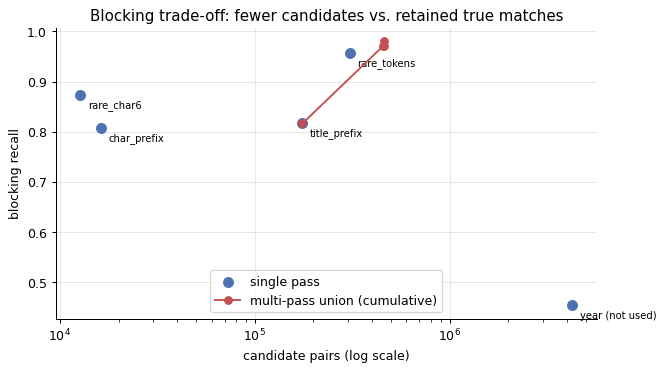

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
single = blocking_df[~blocking_df["pass"].str.startswith("∪")]
union_rows = blocking_df[blocking_df["pass"].str.startswith("∪")]
ax.scatter(single.candidates, single.blocking_recall, s=60, color="#4C72B0", label="single pass", zorder=3)
for _, r in single.iterrows():
    ax.annotate(r["pass"], (r.candidates, r.blocking_recall), xytext=(6, -10), textcoords="offset points", fontsize=8)
ax.plot(union_rows.candidates, union_rows.blocking_recall, "o-", color="#C44E52", label="multi-pass union (cumulative)", zorder=3)
ax.set_xscale("log"); ax.set_xlabel("candidate pairs (log scale)"); ax.set_ylabel("blocking recall")
ax.set_title("Blocking trade-off: fewer candidates vs. retained true matches")
ax.legend(loc="lower center"); plt.tight_layout(); save_fig(fig, "blocking_tradeoff"); plt.show()
BM = key_metrics(CAND_KEYS)
print(f"Final candidate set: {BM['candidates']:,} pairs | reduction ratio {BM['reduction_ratio']:.4%} | blocking recall {BM['blocking_recall']:.2%}")

## 10. Similarity features for all candidate pairs

In [22]:
t0 = time.time()
di_c, si_c = keys_to_pairs(CAND_KEYS)
FEAT = compute_features(di_c, si_c)
FEAT["key"] = CAND_KEYS
FEAT["label"] = np.isin(CAND_KEYS, GOLD_KEYS).astype(np.int8)      # used ONLY for evaluation / ML training
FEAT["split"] = dblp.split.to_numpy()[di_c]
MATCH_TIME_FEATURES = time.time() - t0
print(f"computed {FEAT.shape[1]-5} similarity features for {len(FEAT):,} pairs in {MATCH_TIME_FEATURES:.1f}s")
N_GOLD = {s: len(GOLD_SPLIT[s]) for s in ["train", "val", "test"]}
VAL, TEST, TRAIN = (FEAT[FEAT.split == s].reset_index(drop=True) for s in ["val", "test", "train"])
FEAT.describe().T[["mean", "min", "max"]].round(3).iloc[2:]

computed 14 similarity features for 462,813 pairs in 7.5s


,mean,min,max
title_exact,8.000000e-03,0.000,1.0
title_edit,3.060000e-01,0.000,1.0
title_jac,1.340000e-01,0.000,1.0
title_bi,2.550000e-01,0.000,1.0
title_tri,1.510000e-01,0.000,1.0
title_4g,1.210000e-01,0.000,1.0
author_tok,3.400000e-02,0.000,1.0
author_last,1.500000e-02,0.000,1.0
author_best,2.570000e-01,0.000,1.0
venue_exact,4.100000e-02,0.000,1.0


## 11. Mandatory algorithm comparison (Sections 13, 21, 44)

Each measure is evaluated **on its own** as a matcher over the candidate set: the best threshold is chosen on validation, and precision / recall / F1 are reported on test.

In [23]:
def evaluate_single_score(col, df_val=VAL, df_test=TEST, fill=0.0):
    sv = df_val[col].fillna(fill).to_numpy(); st = df_test[col].fillna(fill).to_numpy()
    T, f_val = best_threshold(sv, df_val.label.to_numpy(), N_GOLD["val"])
    m = threshold_sweep(st, df_test.label.to_numpy(), N_GOLD["test"], [T]).iloc[0]
    return {"measure": col, "best threshold (val)": T, "val F1": f_val,
            "test precision": m.precision, "test recall": m.recall, "test F1": m.f1}

# title: combined score with alpha chosen on validation
alpha_rows = []
for a in np.round(np.arange(0, 1.01, 0.1), 2):
    for df in (VAL, TEST):
        df["_tmp"] = a * df.title_edit + (1 - a) * df.title_jac
    alpha_rows.append({"alpha": a, "val best F1": fast_best_f1(VAL._tmp.to_numpy(), VAL.label.to_numpy(), N_GOLD["val"])})
alpha_df = pd.DataFrame(alpha_rows)
ALPHA = float(alpha_df.loc[alpha_df["val best F1"].idxmax(), "alpha"])
for df in (FEAT, VAL, TEST, TRAIN):
    df["title_combined"] = (ALPHA * df.title_edit + (1 - ALPHA) * df.title_jac).astype(np.float32)
print(f"chosen alpha for S_title = alpha*S_edit + (1-alpha)*S_jaccard : {ALPHA}")

title_cmp = pd.DataFrame([evaluate_single_score(c) for c in
                          ["title_exact", "title_edit", "title_jac", "title_bi", "title_tri", "title_4g", "title_combined"]])
title_cmp["measure"] = title_cmp.measure.map({"title_exact": "Exact equality", "title_edit": "Edit similarity",
    "title_jac": "Token Jaccard", "title_bi": "Bigram Jaccard", "title_tri": "Trigram Jaccard",
    "title_4g": "4-gram Jaccard", "title_combined": f"Combined (α={ALPHA})"})
author_cmp = pd.DataFrame([evaluate_single_score(c) for c in ["author_tok", "author_last", "author_best"]])
author_cmp["measure"] = author_cmp.measure.map({"author_tok": "Token Jaccard (all name tokens)",
    "author_last": "Last-name Jaccard", "author_best": "Avg. best-match name edit similarity"})
venue_cmp = pd.DataFrame([evaluate_single_score(c) for c in ["venue_exact", "venue_tok", "venue_tri"]])
venue_cmp["measure"] = venue_cmp.measure.map({"venue_exact": "Exact normalized venue",
    "venue_tok": "Token Jaccard (+acronym)", "venue_tri": "Trigram Jaccard"})
title_cmp.to_csv(f"{OUT_DIR}/compare_title_measures.csv", index=False)
author_cmp.to_csv(f"{OUT_DIR}/compare_author_measures.csv", index=False)
venue_cmp.to_csv(f"{OUT_DIR}/compare_venue_measures.csv", index=False)
print("TITLE measures"); display(title_cmp.round(4))
print("AUTHOR measures (used alone, so F1 is low — authors alone cannot identify a paper)"); display(author_cmp.round(4))
print("VENUE measures"); display(venue_cmp.round(4))

chosen alpha for S_title = alpha*S_edit + (1-alpha)*S_jaccard : 0.6
TITLE measures
AUTHOR measures (used alone, so F1 is low — authors alone cannot identify a paper)
VENUE measures


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Exact equality,0.300,0.6111,0.7490,0.5507,0.6347
1,Edit similarity,0.715,0.7723,0.7027,0.8541,0.7710
2,Token Jaccard,0.630,0.7601,0.7363,0.8039,0.7686
3,Bigram Jaccard,0.675,0.7866,0.6811,0.8957,0.7738
4,Trigram Jaccard,0.655,0.8073,0.7567,0.8744,0.8113
5,4-gram Jaccard,0.595,0.8113,0.7301,0.8860,0.8005
6,Combined (α=0.6),0.660,0.7939,0.7485,0.8570,0.7991


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Token Jaccard (all name tokens),0.335,0.6696,0.6153,0.7217,0.6643
1,Last-name Jaccard,0.420,0.7048,0.6396,0.7372,0.6849
2,Avg. best-match name edit similarity,0.720,0.7211,0.6281,0.7816,0.6965


,measure,best threshold (val),val F1,test precision,test recall,test F1
0,Exact normalized venue,0.300,0.1247,0.0868,0.2251,0.1253
1,Token Jaccard (+acronym),0.300,0.1332,0.0709,0.3671,0.1188
2,Trigram Jaccard,0.555,0.1353,0.0829,0.2870,0.1286


**Choosing the attribute measure for the record-level score.** Using an attribute *alone* as a matcher is not the same as its usefulness *inside* the weighted score, so the final choice of author and venue measure is made in the weight search below (validation F1 of the full record score).

## 12. Weighted record-level similarity (Sections 23–24)

$$S(A,B)=\frac{\sum_{k\in K} w_k S_k}{\sum_{k\in K} w_k}$$
where *K* = attributes available for both records (missing values are re-normalized, not treated as 0).

A grid search over weights (step 0.05, $\sum w = 1$) and over the author/venue measure is run on the **validation** split.

In [24]:
from src.matching import weighted_score   # S = sum w_k * S_k, renormalized over non-missing fields

grid = [(wt, wa, wv, round(1 - wt - wa - wv, 2))
        for wt in np.round(np.arange(0.30, 0.951, 0.05), 2)
        for wa in np.round(np.arange(0, 0.701, 0.05), 2)
        for wv in np.round(np.arange(0, 0.401, 0.05), 2)
        if 1 - wt - wa - wv > -1e-9]
yv = VAL.label.to_numpy()
t0 = time.time()
search = []
for ac in ["author_tok", "author_last", "author_best"]:
    for vc in ["venue_tok", "venue_tri"]:
        for w in grid:
            search.append({"author": ac, "venue": vc, "w_title": w[0], "w_author": w[1], "w_venue": w[2], "w_year": w[3],
                           "val_best_F1": fast_best_f1(weighted_score(VAL, w, ac, vc), yv, N_GOLD["val"])})
search_df = pd.DataFrame(search).sort_values("val_best_F1", ascending=False).reset_index(drop=True)
print(f"evaluated {len(search_df):,} weight configurations in {time.time()-t0:.1f}s")
best = search_df.iloc[0]
W = tuple(round(float(x), 2) for x in (best.w_title, best.w_author, best.w_venue, best.w_year))
AUTHOR_COL, VENUE_COL = best.author, best.venue
print(f"BEST on validation: weights (title, author, venue, year) = {W}, author measure = {AUTHOR_COL}, venue measure = {VENUE_COL}")
search_df.to_csv(f"{OUT_DIR}/weight_search.csv", index=False)
search_df.head(10).round(4)

evaluated 3,738 weight configurations in 27.6s
BEST on validation: weights (title, author, venue, year) = (0.45, 0.3, 0.0, 0.25), author measure = author_best, venue measure = venue_tri


,author,venue,w_title,w_author,w_venue,w_year,val_best_F1
0,author_best,venue_tri,0.45,0.30,0.0,0.25,0.8787
1,author_best,venue_tok,0.45,0.30,0.0,0.25,0.8787
2,author_best,venue_tri,0.45,0.35,0.0,0.20,0.8727
3,author_best,venue_tok,0.45,0.35,0.0,0.20,0.8727
4,author_best,venue_tok,0.40,0.35,0.0,0.25,0.8706
5,author_best,venue_tri,0.40,0.35,0.0,0.25,0.8706
6,author_best,venue_tri,0.45,0.25,0.0,0.30,0.8706
7,author_best,venue_tok,0.45,0.25,0.0,0.30,0.8706
8,author_best,venue_tri,0.40,0.30,0.0,0.30,0.8701
9,author_best,venue_tok,0.40,0.30,0.0,0.30,0.8701


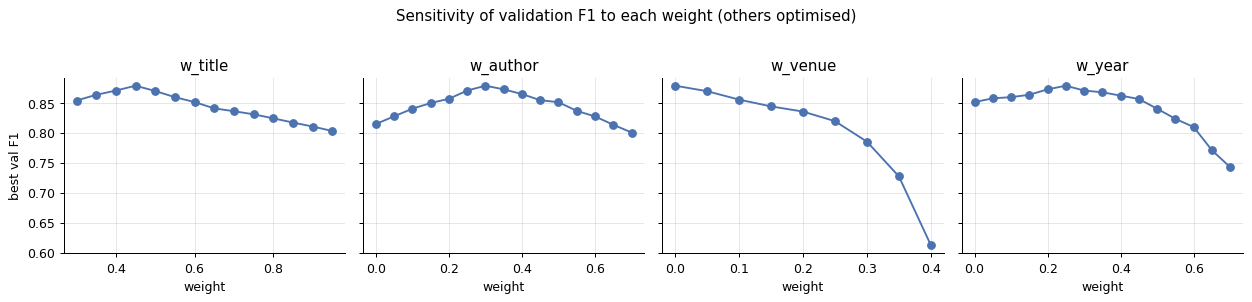

,missing values,val best F1
0,re-normalize weights (Sec. 24),0.8787
1,treat missing as 0,0.8384


In [25]:
# How important is each weight? best achievable validation F1 for each value of one weight
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
sub = search_df[(search_df.author == AUTHOR_COL) & (search_df.venue == VENUE_COL)]
for a, col in zip(ax, ["w_title", "w_author", "w_venue", "w_year"]):
    s = sub.groupby(col).val_best_F1.max()
    a.plot(s.index, s.values, "o-", color="#4C72B0"); a.set_title(col); a.set_xlabel("weight")
ax[0].set_ylabel("best val F1")
fig.suptitle("Sensitivity of validation F1 to each weight (others optimised)", y=1.03)
plt.tight_layout(); save_fig(fig, "weight_sensitivity"); plt.show()

# ablation: missing-value re-normalization vs. treating missing as 0
abl = []
for renorm in (True, False):
    s = weighted_score(VAL, W, AUTHOR_COL, VENUE_COL, renormalize=renorm)
    abl.append({"missing values": "re-normalize weights (Sec. 24)" if renorm else "treat missing as 0",
                "val best F1": fast_best_f1(s, yv, N_GOLD["val"])})
pd.DataFrame(abl).round(4)

## 13. Threshold analysis & confidence bands (Sections 33, 35, 41)

In [26]:
for df in (FEAT, VAL, TEST, TRAIN):
    df["score"] = weighted_score(df, W, AUTHOR_COL, VENUE_COL)

MANDATORY_T = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
FINE_T = np.round(np.arange(0.40, 0.991, 0.01), 2)
sweep_val = threshold_sweep(VAL.score, VAL.label, N_GOLD["val"], FINE_T)
sweep_test_mand = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], MANDATORY_T)
THRESHOLD = float(sweep_val.loc[sweep_val.f1.idxmax(), "threshold"])
print(f"Operating threshold chosen on VALIDATION: T = {THRESHOLD}")
sweep_test_mand.to_csv(f"{OUT_DIR}/threshold_sweep_test.csv", index=False)
sweep_val.to_csv(f"{OUT_DIR}/threshold_sweep_val.csv", index=False)
print("Mandatory thresholds on the TEST split:")
sweep_test_mand.round(4)

Operating threshold chosen on VALIDATION: T = 0.69
Mandatory thresholds on the TEST split:


,threshold,TP,FP,FN,precision,recall,f1
0,0.50,1016,897,19,0.5311,0.9816,0.6893
1,0.60,993,376,42,0.7253,0.9594,0.8261
2,0.70,904,121,131,0.8820,0.8734,0.8777
3,0.75,838,62,197,0.9311,0.8097,0.8661
4,0.80,748,37,287,0.9529,0.7227,0.8220
5,0.85,649,30,386,0.9558,0.6271,0.7573
6,0.90,528,25,507,0.9548,0.5101,0.6650
7,0.95,374,25,661,0.9373,0.3614,0.5216


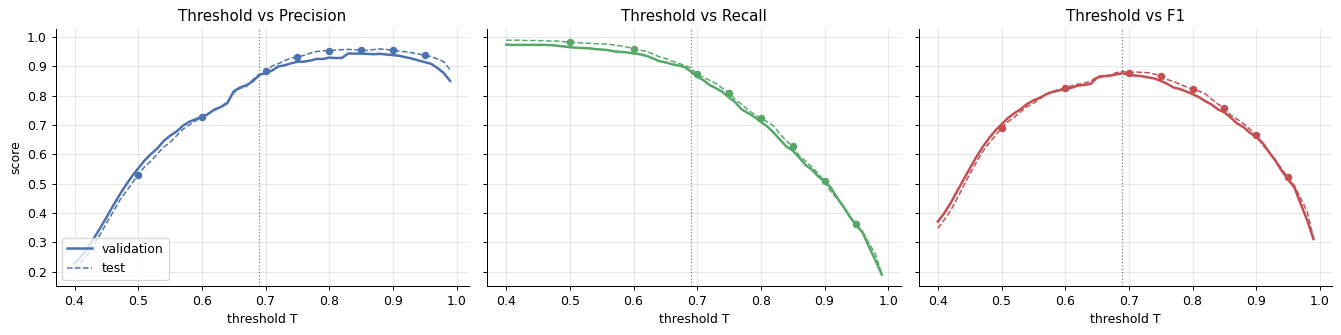

In [27]:
sweep_test_fine = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], FINE_T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, m, c in zip(ax, ["precision", "recall", "f1"], ["#4C72B0", "#55A868", "#C44E52"]):
    a.plot(sweep_val.threshold, sweep_val[m], color=c, lw=2, label="validation")
    a.plot(sweep_test_fine.threshold, sweep_test_fine[m], color=c, lw=1.2, ls="--", label="test")
    a.scatter(MANDATORY_T, sweep_test_mand[m], color=c, zorder=3, s=25)
    a.axvline(THRESHOLD, color="grey", ls=":", lw=1)
    a.set_title(f"Threshold vs {m.capitalize() if m!='f1' else 'F1'}"); a.set_xlabel("threshold T")
ax[0].set_ylabel("score"); ax[0].legend(loc="lower left")
ax[2].annotate(f"chosen T={THRESHOLD}", (THRESHOLD, 0.05), xytext=(5, 0), textcoords="offset points", fontsize=8, color="grey")
plt.tight_layout(); save_fig(fig, "threshold_curves"); plt.show()

**Confidence bands from data, not guesses.** On the validation split:
- **High-confidence** lower bound $T_{high}$ = smallest threshold whose predictions are ≥ 97 % precise;
- **Likely non-match** upper bound $T_{low}$ = largest threshold below which at most 1 % of the true matches found by blocking fall;
- everything in between goes to **manual review** in the web app.

In [28]:
# boundaries chosen on VALIDATION only (see src/evaluation/bands.py for the rule)
T_HIGH, T_LOW = choose_bands(VAL.score, VAL.label, THRESHOLD, grid=FINE_T)

def band(s):
    return assign_band(s, T_HIGH, T_LOW)

for df in (FEAT, VAL, TEST, TRAIN):
    df["band"] = band(df.score.to_numpy())
band_df = (TEST.groupby("band").agg(pairs=("label", "size"), true_matches=("label", "sum"))
           .assign(match_rate=lambda x: (x.true_matches / x.pairs).round(4))
           .reindex(["High confidence", "Manual review", "Likely non-match"]))
print(f"Bands (chosen on validation):  S ≥ {T_HIGH} high confidence | {T_LOW} ≤ S < {T_HIGH} manual review | S < {T_LOW} likely non-match")
print("How the bands behave on the TEST split:")
band_df

Bands (chosen on validation):  S ≥ 0.95 high confidence | 0.49 ≤ S < 0.95 manual review | S < 0.49 likely non-match
How the bands behave on the TEST split:


,pairs,true_matches,match_rate
band,,,
High confidence,398,373,0.9372
Manual review,1638,645,0.3938
Likely non-match,90980,5,0.0001


## 13b. Student 1's similarity study, and Student 1's settings in the full pipeline

Student 1 (`src/compare_similarity.py`) compared the title measures, α, the two author methods and four weight settings on a **sample**: every gold pair against one random and one "same first title word" non-match. Here that study is run with Student 1's own code (`src/evaluation/student1_study.py`), changed in one way only: it uses the gold pairs of the **train and validation** DBLP records, so the test split stays untouched.

Then Student 1's settings (α = 0.4, token-Jaccard authors, trigram venue, the example weights 0.50/0.30/0.10/0.10 and the three other weight trials) are run through the **full pipeline** — blocking, all candidate pairs, threshold chosen on validation, reported on test — next to the setting tuned on validation in Section 12.

**Why the numbers differ:** Student 1's sample is about 50 % matches; the real candidate set is about 1 % matches. With 100× more non-matches, the same score produces many more false positives, so precision and F1 are much lower in the full pipeline. The sample is useful for *ranking* measures, not for reporting final performance.

In [29]:
from src.evaluation.student1_study import load_student1_data, non_test_gold, run_study

t0 = time.time()
_s1_dblp, _s1_scholar, _s1_gold = load_student1_data()
S1_STUDY = run_study(_s1_dblp, _s1_scholar, non_test_gold(_s1_dblp, _s1_gold, seed=SEED))
for name, df in S1_STUDY.items():
    df.to_csv(f"{OUT_DIR}/student1_{name}.csv", index=False)
print(f"Student 1's study on train+val gold pairs ({time.time()-t0:.0f}s):", S1_STUDY["sample"].to_dict("records")[0])
print("Title measures (vs same-first-word non-matches)")
display(S1_STUDY["title_measures"].query("nonmatches == 'same first word'").round(3))
print("Alpha"); display(S1_STUDY["alpha"].round(3))
print("Author methods"); display(S1_STUDY["author_methods"].round(3))


Student 1's study on train+val gold pairs (26s): {'gold_pairs': 4312, 'random_nonmatches': 4312, 'same_first_word_nonmatches': 3455}
Title measures (vs same-first-word non-matches)
Alpha
Author methods


,nonmatches,measure,gold_avg,nonmatch_avg,best_T,precision,recall,f1
7,same first word,exact,0.532,0.004,0.5,0.994,0.532,0.693
8,same first word,edit,0.896,0.346,0.5,0.954,0.971,0.962
9,same first word,jaccard,0.836,0.127,0.5,0.978,0.920,0.948
10,same first word,bigram,0.901,0.249,0.5,0.973,0.986,0.979
11,same first word,trigram,0.880,0.143,0.5,0.980,0.967,0.974
12,same first word,fourgram,0.867,0.112,0.5,0.984,0.951,0.967
13,same first word,combined,0.860,0.214,0.5,0.977,0.944,0.960


,alpha,gold_avg,nonmatch_avg,best_T,precision,recall,f1
0,0.0,0.836,0.127,0.5,0.978,0.920,0.948
1,0.2,0.848,0.171,0.5,0.980,0.923,0.951
2,0.4,0.860,0.214,0.5,0.977,0.944,0.960
3,0.6,0.872,0.258,0.5,0.976,0.958,0.967
4,0.8,0.884,0.302,0.5,0.970,0.968,0.969
5,1.0,0.896,0.346,0.5,0.954,0.971,0.962


,method,gold_avg,nonmatch_avg,best_T,precision,recall,f1
0,token jaccard,0.625,0.046,0.5,0.974,0.647,0.777
1,best name match,0.855,0.272,0.5,0.959,0.910,0.934


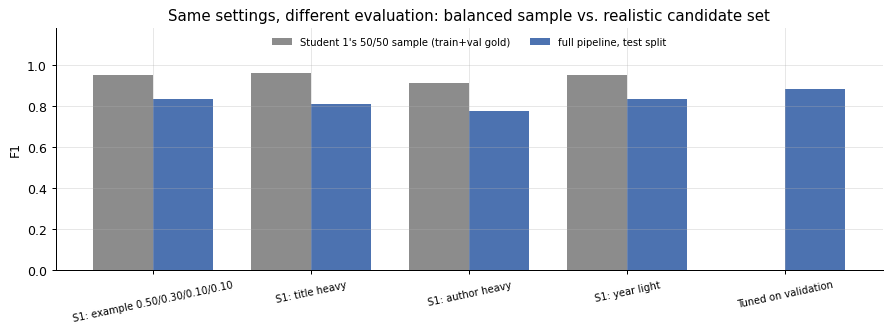

,setting,alpha,"weights (t,a,v,y)",author,venue,Student 1 sample F1,val F1,threshold (val),test precision,test recall,test F1
0,Student 1: example 0.50/0.30/0.10/0.10,0.4,"(0.5, 0.3, 0.1, 0.1)",author_tok,venue_tri,0.9483,0.8217,0.56,0.8106,0.8560,0.8327
1,Student 1: title heavy,0.4,"(0.7, 0.2, 0.05, 0.05)",author_tok,venue_tri,0.9609,0.8127,0.57,0.7472,0.8879,0.8115
2,Student 1: author heavy,0.4,"(0.35, 0.45, 0.1, 0.1)",author_tok,venue_tri,0.9095,0.7758,0.48,0.6969,0.8773,0.7767
3,Student 1: year light,0.4,"(0.55, 0.3, 0.1, 0.05)",author_tok,venue_tri,0.9500,0.8146,0.59,0.8406,0.8251,0.8328
4,Tuned on validation (Section 12),0.6,"(0.45, 0.3, 0.0, 0.25)",author_best,venue_tri,NaN,0.8759,0.69,0.8726,0.8937,0.8831


In [30]:
from src.evaluation.student1_study import S1C       # Student 1's WEIGHT_TRIALS

def pipeline_eval(alpha, w, author_col, venue_col):
    """threshold chosen on VALIDATION (same grid as Section 13), reported once on TEST"""
    V = VAL.assign(title_combined=alpha * VAL.title_edit + (1 - alpha) * VAL.title_jac)
    Te = TEST.assign(title_combined=alpha * TEST.title_edit + (1 - alpha) * TEST.title_jac)
    sv = threshold_sweep(weighted_score(V, w, author_col, venue_col), V.label, N_GOLD["val"], FINE_T)
    T = float(sv.loc[sv.f1.idxmax(), "threshold"])
    m = threshold_sweep(weighted_score(Te, w, author_col, venue_col), Te.label, N_GOLD["test"], [T]).iloc[0]
    return {"val F1": float(sv.f1.max()), "threshold (val)": T, "test precision": m.precision,
            "test recall": m.recall, "test F1": m.f1}

rows = []
s1_sample = S1_STUDY["weight_trials"].set_index("setting").f1
for label, wd in S1C.WEIGHT_TRIALS:
    w = (wd["title"], wd["author"], wd["venue"], wd["year"])
    rows.append({"setting": f"Student 1: {label}", "alpha": 0.4, "weights (t,a,v,y)": w, "author": "author_tok",
                 "venue": "venue_tri", "Student 1 sample F1": s1_sample[label], **pipeline_eval(0.4, w, "author_tok", "venue_tri")})
rows.append({"setting": "Tuned on validation (Section 12)", "alpha": ALPHA, "weights (t,a,v,y)": W, "author": AUTHOR_COL,
             "venue": VENUE_COL, "Student 1 sample F1": np.nan, **pipeline_eval(ALPHA, W, AUTHOR_COL, VENUE_COL)})
s1_settings_df = pd.DataFrame(rows)
s1_settings_df.to_csv(f"{OUT_DIR}/student1_settings_in_pipeline.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(s1_settings_df)); wbar = 0.38
ax.bar(x - wbar / 2, s1_settings_df["Student 1 sample F1"], wbar, label="Student 1's 50/50 sample (train+val gold)", color="#8C8C8C")
ax.bar(x + wbar / 2, s1_settings_df["test F1"], wbar, label="full pipeline, test split", color="#4C72B0")
ax.set_xticks(x); ax.set_xticklabels([s.replace("Student 1: ", "S1: ").replace(" (Section 12)", "") for s in s1_settings_df.setting],
                                     rotation=12, fontsize=8)
ax.set_ylim(0, 1.18); ax.set_ylabel("F1"); ax.legend(loc="upper center", ncol=2, fontsize=8, frameon=False)
ax.set_title("Same settings, different evaluation: balanced sample vs. realistic candidate set")
plt.tight_layout(); save_fig(fig, "student1_vs_pipeline"); plt.show()
s1_settings_df.round(4)


## 14. Optional ML extension — Logistic Regression & Decision Tree (Sections 36–38)

Code: `src/ml/train.py`. The best Logistic Regression is saved to `outputs/lr_model.joblib` for the web app.

Feature vector $X = [S_{title}, S_{author}, S_{venue}, S_{year}, TitleLengthRatio]$ plus three missing-value indicators (missing values are set to 0 and flagged, so the model can learn how to treat them).
- Train on the **train** split candidate pairs; keep **all** positives and a reproducible sample of negatives (`random_state=42`, 20 negatives per positive).
- Choose hyper-parameters and the probability threshold on **validation** (full, unsampled).
- Report once on **test**. CPU only, runs in seconds.

In [31]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.ml import FEATURE_NAMES, train_models, save_model, sample_training_pairs
from src.ml import make_X as _make_X

def make_X(df):
    """feature matrix with the author / venue measures chosen on validation"""
    return _make_X(df, AUTHOR_COL, VENUE_COL)

# train on TRAIN candidate pairs (all positives + 20 sampled negatives each), choose on VALIDATION
ml_df, ML_BEST, ml_info = train_models(TRAIN, VAL, N_GOLD["val"], AUTHOR_COL, VENUE_COL, seed=SEED)
print(f"training pairs: {ml_info['train_pairs']:,} ({ml_info['positives']:,} positive, "
      f"{ml_info['negatives_sampled']:,} sampled negative of {ml_info['negatives_available']:,})")
ml_df.round(4)


training pairs: 65,562 (3,122 positive, 62,440 sampled negative of 274,949)


,model,param,val F1,threshold
0,Logistic Regression,C=0.01,0.8851,0.78
1,Logistic Regression,C=0.1,0.8860,0.74
2,Logistic Regression,C=1,0.8881,0.73
3,Logistic Regression,C=10,0.8893,0.72
4,Decision Tree,max_depth=3,0.8815,0.69
5,Decision Tree,max_depth=4,0.8875,0.78
6,Decision Tree,max_depth=5,0.8947,0.75
7,Decision Tree,max_depth=6,0.8985,0.71
8,Decision Tree,max_depth=8,0.9014,0.71
9,Decision Tree,max_depth=10,0.9014,0.71


best LR: C=10  (val F1 0.8893, T = 0.72)
best DT: max_depth=10  (val F1 0.9014, T = 0.71)
saved: c:\Users\Acer\Documents\GitHub\EntityGuard/outputs/lr_model.joblib


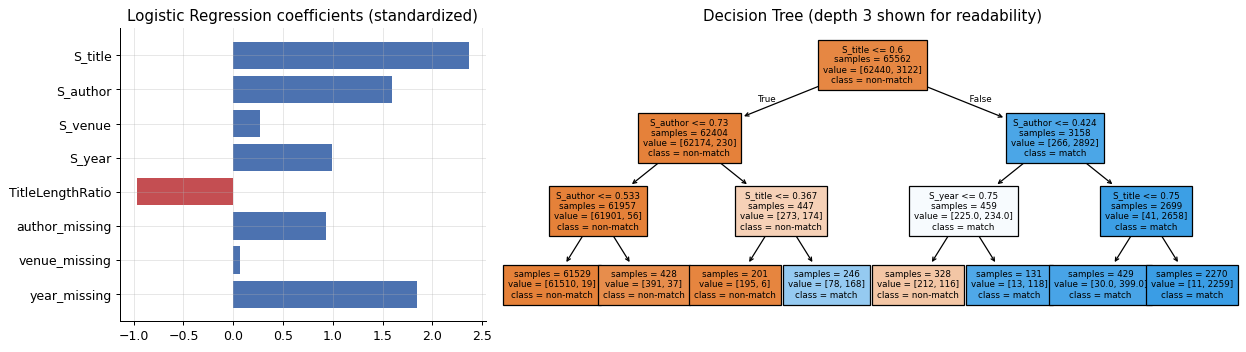

In [32]:
LR_MODEL, LR_T = ML_BEST["LR"]["model"], ML_BEST["LR"]["threshold"]
DT_MODEL, DT_T = ML_BEST["DT"]["model"], ML_BEST["DT"]["threshold"]
print(f"best LR: {ML_BEST['LR']['param']}  (val F1 {ML_BEST['LR']['val_f1']:.4f}, T = {LR_T})")
print(f"best DT: {ML_BEST['DT']['param']}  (val F1 {ML_BEST['DT']['val_f1']:.4f}, T = {DT_T})")
print("saved:", save_model(ML_BEST["LR"], AUTHOR_COL, VENUE_COL, path=f"{OUT_DIR}/lr_model.joblib"))

for df in (FEAT, VAL, TEST):
    X = make_X(df)
    df["lr_prob"] = LR_MODEL.predict_proba(X)[:, 1]
    df["dt_prob"] = DT_MODEL.predict_proba(X)[:, 1]

coef = LR_MODEL[-1].coef_[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].barh(FEATURE_NAMES, coef, color=["#4C72B0" if c > 0 else "#C44E52" for c in coef])
ax[0].set_title("Logistic Regression coefficients (standardized)"); ax[0].invert_yaxis()
_tr = sample_training_pairs(TRAIN, seed=SEED)          # the same reproducible training sample
X_tr, y_tr = make_X(_tr), _tr.label.to_numpy()
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED).fit(X_tr, y_tr)
plot_tree(small_tree, feature_names=FEATURE_NAMES, class_names=["non-match", "match"], filled=True, ax=ax[1], fontsize=7, impurity=False)
ax[1].set_title("Decision Tree (depth 3 shown for readability)")
plt.tight_layout(); save_fig(fig, "ml_models"); plt.show()

## 15. Final method comparison (Section 39)

| Method | What it does |
|---|---|
| Baseline 1 | exact normalized title, all pairs (hash join) |
| Baseline 2 | single fuzzy-title score (edit similarity), **all 168 M pairs, no blocking** |
| Method 3 | weighted multi-attribute similarity, **all 168 M pairs, no blocking** |
| Method 4 | weighted similarity **+ multi-pass blocking** |
| Method 5 | Logistic Regression on blocked candidates (and Decision Tree) |

Methods 2 and 3 are computed brute-force with fast C++/sparse-matrix code in chunks of DBLP records so they fit in Colab memory (about a minute). This lets us measure honestly what blocking costs in recall and saves in work. With the pure-Python scorer the same brute-force run would take the number of hours printed in Section 5.1.

In [33]:
RUN_BRUTE_FORCE = True    # set False to skip (~1–2 min on Colab)

def brute_force(min_keep=0.45, chunk=128):
    """score every DBLP x Scholar pair; keep pairs above min_keep for B2 (title edit) and M3 (weighted)"""
    ac_space = SPACES[AUTHOR_COL] if AUTHOR_COL in SPACES else SPACES["author_last"]
    keep_b2, keep_m3 = [], []
    t0 = time.time()
    for start in range(0, N_D, chunk):
        rows = np.arange(start, min(start + chunk, N_D))
        edit = process.cdist(D_T[rows], S_T, scorer=RFLevenshtein.normalized_similarity, dtype=np.float32, workers=-1)
        tj = SPACES["title_tok"].matrix(rows)
        title = ALPHA * edit + (1 - ALPHA) * np.nan_to_num(tj)
        au = ac_space.matrix(rows); ve = SPACES[VENUE_COL].matrix(rows)
        yr = year_score_vec(D_Y[rows][:, None], S_Y[None, :])
        num = W[0] * title; den = np.full(title.shape, W[0], dtype=np.float32)
        for wk, s in ((W[1], au), (W[2], ve), (W[3], yr)):
            ok = ~np.isnan(s); num += wk * np.where(ok, s, 0); den += wk * ok
        S = num / den
        r, c = np.nonzero(edit >= min_keep); keep_b2.append(np.column_stack([rows[r], c, edit[r, c]]))
        r, c = np.nonzero(S >= min_keep); keep_m3.append(np.column_stack([rows[r], c, S[r, c]]))
    elapsed = time.time() - t0
    to_df = lambda arrs: pd.DataFrame(np.vstack(arrs), columns=["di", "si", "score"]).astype({"di": int, "si": int})
    return to_df(keep_b2), to_df(keep_m3), elapsed

def eval_pairs_df(df, T, split):
    sub = df[(df.score >= T) & (dblp.split.to_numpy()[df.di.to_numpy()] == split)]
    keys = sub.di.to_numpy().astype(np.int64) * N_S + sub.si.to_numpy()
    g = np.array([D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD_SPLIT[split]], dtype=np.int64)
    tp = int(np.isin(keys, g).sum()); fp = len(keys) - tp; fn = len(g) - tp
    p = tp / (tp + fp) if tp + fp else 0; r = tp / len(g)
    return {"TP": tp, "FP": fp, "FN": fn, "precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0}

def tune_on_val(df):
    labels = np.isin(df.di.to_numpy().astype(np.int64) * N_S + df.si.to_numpy(), GOLD_KEYS)
    m = dblp.split.to_numpy()[df.di.to_numpy()] == "val"
    return best_threshold(df.score.to_numpy()[m], labels[m], N_GOLD["val"], grid=np.round(np.arange(0.45, 0.996, 0.01), 2))[0]

comparison = []
b1 = baseline_df[(baseline_df.method == "Exact normalized title") & (baseline_df.split == "test")].iloc[0]
comparison.append({"method": "B1  Exact normalized title", "pairs scored": "hash join", "time_s": t_exact,
                   "threshold": "—", **{k: b1[k] for k in ["TP", "FP", "FN", "precision", "recall", "f1"]}})
if RUN_BRUTE_FORCE:
    B2_DF, M3_DF, BF_TIME = brute_force()
    T2, T3 = tune_on_val(B2_DF), tune_on_val(M3_DF)
    comparison.append({"method": "B2  Fuzzy title (edit sim), no blocking", "pairs scored": f"{P_ALL:,}", "time_s": BF_TIME,
                       "threshold": T2, **eval_pairs_df(B2_DF, T2, "test")})
    comparison.append({"method": "M3  Weighted multi-attribute, no blocking", "pairs scored": f"{P_ALL:,}", "time_s": BF_TIME,
                       "threshold": T3, **eval_pairs_df(M3_DF, T3, "test")})
m4 = threshold_sweep(TEST.score, TEST.label, N_GOLD["test"], [THRESHOLD]).iloc[0]
comparison.append({"method": "M4  Weighted + multi-pass blocking", "pairs scored": f"{len(FEAT):,}",
                   "time_s": BLOCKING_TIME + MATCH_TIME_FEATURES, "threshold": THRESHOLD,
                   **m4[["TP", "FP", "FN", "precision", "recall", "f1"]].to_dict()})
for name, col, T in [("M5  Logistic Regression + blocking", "lr_prob", LR_T), ("M5b Decision Tree + blocking", "dt_prob", DT_T)]:
    m = threshold_sweep(TEST[col], TEST.label, N_GOLD["test"], [T]).iloc[0]
    comparison.append({"method": name, "pairs scored": f"{len(FEAT):,}", "time_s": BLOCKING_TIME + MATCH_TIME_FEATURES,
                       "threshold": T, **m[["TP", "FP", "FN", "precision", "recall", "f1"]].to_dict()})
comparison_df = pd.DataFrame(comparison)
for c in ["TP", "FP", "FN"]:
    comparison_df[c] = comparison_df[c].astype(int)
comparison_df.to_csv(f"{OUT_DIR}/method_comparison.csv", index=False)
print("All numbers are on the untouched TEST split; thresholds were chosen on validation.")
comparison_df.style.format({"time_s": "{:.1f}", "precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}"})

All numbers are on the untouched TEST split; thresholds were chosen on validation.


,method,pairs scored,time_s,threshold,TP,FP,FN,precision,recall,f1
0,B1 Exact normalized title,hash join,0.1,—,570,191,465,0.7490,0.5507,0.6347
1,"B2 Fuzzy title (edit sim), no blocking","168,112,008",64.8,0.740000,867,335,168,0.7213,0.8377,0.7751
2,"M3 Weighted multi-attribute, no blocking","168,112,008",64.8,0.620000,870,119,165,0.8797,0.8406,0.8597
3,M4 Weighted + multi-pass blocking,"462,813",14.0,0.690000,925,135,110,0.8726,0.8937,0.8831
4,M5 Logistic Regression + blocking,"462,813",14.0,0.720000,943,131,92,0.8780,0.9111,0.8943
5,M5b Decision Tree + blocking,"462,813",14.0,0.710000,934,104,101,0.8998,0.9024,0.9011


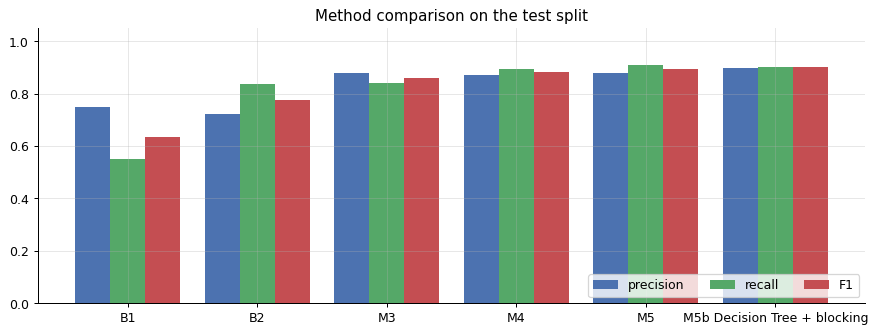

In [34]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(comparison_df)); wbar = 0.27
for k, (m, c) in enumerate(zip(["precision", "recall", "f1"], ["#4C72B0", "#55A868", "#C44E52"])):
    ax.bar(x + (k - 1) * wbar, comparison_df[m], wbar, label=m if m != "f1" else "F1", color=c)
ax.set_xticks(x); ax.set_xticklabels([s.split("  ")[0] for s in comparison_df.method])
ax.set_ylim(0, 1.05); ax.set_title("Method comparison on the test split"); ax.legend(ncol=3, loc="lower right")
plt.tight_layout(); save_fig(fig, "method_comparison"); plt.show()

**How to read the comparison (this run):** multi-pass blocking scores only about 0.3 % of the 168 M pairs but keeps about 98 % of the gold matches. The blocked pipeline (M4) is *better* than the brute-force weighted score (M3): blocking throws away many accidental look-alike pairs before they can become false positives, so the threshold chosen on validation can be lower and recall rises. Weighted multi-attribute scoring beats any single title score mainly through the **author** attribute; with Student 1's normalization, validation gives the **venue a weight of 0** (venue alone has F1 ≈ 0.13). Both ML models beat the tuned rule-based score on test (Decision Tree ≈ +1.8 F1 points, Logistic Regression ≈ +1.1), mainly through higher recall. The exact numbers are in the table above and in `outputs/summary.json`.

## 16. Error analysis — 20 false positives & 20 false negatives (Section 45)

Errors come from Method 4 on the **test** split; false negatives include gold pairs that blocking never produced. Each case first gets **automatic tags** from simple rules. Every case was then **read by hand** and given Section 45 causes in `manual_cause` (primary cause first) with a short explanation in `manual_note` (`outputs/error_analysis_40_cases.csv`). The manual labels are kept when the notebook is re-run, as long as the same cases are sampled.

In [35]:
def tag_causes(r):
    c = []
    if r.get("in_candidates") is False:
        c.append("Missed by blocking")
    if pd.isna(r.author_s) or pd.isna(r.author_d): c.append("Missing author")
    if pd.isna(r.venue_s) or pd.isna(r.venue_d): c.append("Missing venue")
    elif not pd.isna(r.S_venue) and r.S_venue < 0.2: c.append("Abbreviated / different venue")
    if pd.isna(r.year_s): c.append("Missing year")
    elif not pd.isna(r.year_d) and r.year_d != r.year_s: c.append("Wrong / different year")
    if len(str(r.title_d).split()) <= 3: c.append("Short generic title")
    if r.S_title >= 0.9 and r.kind == "FP": c.append("Very similar titles")
    if r.kind == "FN" and r.S_title < 0.75:
        if r.title_tri >= 0.6 and r.title_jac < 0.5: c.append("Glued words in Scholar title")
        elif r.len_ratio < 0.7: c.append("Title length mismatch (extra / truncated text)")
        else: c.append("Severe spelling variation")
    if r.kind == "FN" and not pd.isna(r.S_author) and 0 < r.S_author < 0.5: c.append("Different author lists / ordering")
    return "; ".join(c) if c else "Other"

def error_rows(df, kind):
    out = pd.DataFrame({
        "kind": kind, "dblp_id": dblp.id.to_numpy()[df.di], "scholar_id": scholar.id.to_numpy()[df.si],
        "title_d": dblp.title.to_numpy()[df.di], "title_s": scholar.title.to_numpy()[df.si],
        "author_d": dblp.authors.to_numpy()[df.di], "author_s": scholar.authors.to_numpy()[df.si],
        "venue_d": dblp.venue.to_numpy()[df.di], "venue_s": scholar.venue.to_numpy()[df.si],
        "year_d": dblp.year.to_numpy()[df.di], "year_s": scholar.year.to_numpy()[df.si],
        "S_title": df.title_combined.values, "S_author": df[AUTHOR_COL].values, "S_venue": df[VENUE_COL].values,
        "S_year": df.year.values, "score": df.score.values, "title_tri": df.title_tri.values, "title_jac": df.title_jac.values,
        "len_ratio": df.len_ratio.values, "in_candidates": df["in_candidates"].values})
    out["auto_causes"] = out.apply(tag_causes, axis=1)
    out["manual_cause"] = ""; out["manual_note"] = ""
    return out

pred = TEST.score >= THRESHOLD
fp_df = TEST[pred & (TEST.label == 0)].assign(in_candidates=True)
fn_in = TEST[~pred & (TEST.label == 1)].assign(in_candidates=True)
# sorted: iterating a set of strings gives a different order in every Python process, which would change the sample
test_gold_keys = np.array(sorted(D_IDX[d] * N_S + S_IDX[s] for d, s in GOLD_SPLIT["test"]), dtype=np.int64)
missed = test_gold_keys[~np.isin(test_gold_keys, CAND_KEYS)]
fn_out = compute_features(*keys_to_pairs(missed)) if len(missed) else pd.DataFrame()
if len(fn_out):
    fn_out["title_combined"] = ALPHA * fn_out.title_edit + (1 - ALPHA) * fn_out.title_jac
    fn_out["score"] = weighted_score(fn_out, W, AUTHOR_COL, VENUE_COL); fn_out["in_candidates"] = False
fn_all = pd.concat([fn_in, fn_out], ignore_index=True)
print(f"test errors: {len(fp_df)} false positives | {len(fn_all)} false negatives "
      f"({len(fn_in)} below threshold, {len(fn_out)} missed by blocking)")

FP20 = error_rows(fp_df.sample(min(20, len(fp_df)), random_state=SEED), "FP")
FN20 = error_rows(fn_all.sample(min(20, len(fn_all)), random_state=SEED), "FN")
errors_df = pd.concat([FP20, FN20], ignore_index=True)
# keep manual labels from an earlier run for cases that are sampled again (re-running must not erase hand work)
_prev = f"{OUT_DIR}/error_analysis_40_cases.csv"
if os.path.exists(_prev):
    _old = pd.read_csv(_prev, dtype=str, keep_default_na=False)
    _note = _old.manual_note if "manual_note" in _old else [""] * len(_old)
    _keep = {(k, d, s): (m, n) for k, d, s, m, n in zip(_old.kind, _old.dblp_id, _old.scholar_id, _old.manual_cause, _note) if m}
    _lab = [_keep.get(k, ("", "")) for k in zip(errors_df.kind, errors_df.dblp_id, errors_df.scholar_id)]
    errors_df["manual_cause"] = [m for m, _ in _lab]; errors_df["manual_note"] = [n for _, n in _lab]
    print(f"kept {sum(m != '' for m in errors_df.manual_cause)} manual labels from the previous run "
          f"({len(_keep)} existed; the rest belong to cases not sampled this time)")
errors_df.to_csv(f"{OUT_DIR}/error_analysis_40_cases.csv", index=False)
show_cols = ["kind", "title_d", "title_s", "year_d", "year_s", "S_title", "S_author", "score", "auto_causes"]
display(FP20[show_cols].round(3))
display(FN20[show_cols].round(3))

test errors: 135 false positives | 110 false negatives (98 below threshold, 12 missed by blocking)
kept 39 manual labels from the previous run (39 existed; the rest belong to cases not sampled this time)


,kind,title_d,title_s,year_d,year_s,S_title,S_author,score,auto_causes
0,FP,Sybase Replication Server,Sybase replication Server,1994,NaN,1.000,0.333,0.733,Abbreviated / different venue; Missing year; Short generic title; Very simil...
1,FP,An Ultra Highly Available DBMS,Designing an ultra highly available DBMS (tutorial session),2000,2000.0,0.529,0.854,0.744,Abbreviated / different venue
2,FP,Guest editor's introduction,Guest Editorâ??s Introduction,2003,2003.0,1.000,NaN,1.000,Missing author; Missing venue; Short generic title; Very similar titles
3,FP,Diluting ACID,Diluting ACID.,1999,1999.0,1.000,0.226,0.768,Short generic title; Very similar titles
4,FP,Editor's Notes,Editor's notes,1998,NaN,1.000,0.273,0.709,Abbreviated / different venue; Missing year; Short generic title; Very simil...
5,FP,Mind Your Vocabulary: Query Mapping Across Heterogeneous Information Sources,Approximate Query Translation Across Heterogeneous Information Sources,1999,NaN,0.574,0.889,0.700,Missing venue; Missing year
6,FP,Fast Algorithms for Mining Association Rules in Large Databases,Fast Algorithms for Mining Generalized Association Rules,1994,NaN,0.561,1.000,0.736,Abbreviated / different venue; Missing year
7,FP,Incremental Computation of Nested Relational Query Expressions,Incremental Computation of Time-Varying Query Expressions,1995,NaN,0.668,0.909,0.764,Missing venue; Missing year
8,FP,Checking the Temporal Integrity of Interactive Multimedia Documents,Temporal Integrity Constraints in Interactive Multimedia Documents,2000,NaN,0.686,0.862,0.756,Missing venue; Missing year
9,FP,Sleepers and Workaholics: Caching Strategies in Mobile Environments,Sleepers and Workoholics-Cache Invalidation Strategies for Mobile and Wirele...,1995,NaN,0.593,0.944,0.734,Abbreviated / different venue; Missing year


,kind,title_d,title_s,year_d,year_s,S_title,S_author,score,auto_causes
0,FN,Sybase Replication Server,The Sybase Replication Server Project,1994,1993.0,0.755,0.529,0.623,Abbreviated / different venue; Wrong / different year; Short generic title
1,FN,Aurora: A Data Stream Management System,Aurora: A Data Stream Management System (demo description),2003,NaN,0.693,0.659,0.680,Missing year; Title length mismatch (extra / truncated text)
2,FN,Fast Algorithms for Mining Association Rules in Large Databases,"Agrawal, R.; Srikant, R.: Fast Algorithms for Mining Association Rules",1994,NaN,0.440,0.722,0.553,Abbreviated / different venue; Missing year; Severe spelling variation
3,FN,"LH* - A Scalable, Distributed Data Structure",Distributed Data Structure,1996,2005.0,0.651,0.530,0.452,Wrong / different year; Title length mismatch (extra / truncated text)
4,FN,The Dangers of Replication and a Solution,The Danger of Replication and a Solution,1996,NaN,0.779,0.295,0.585,Abbreviated / different venue; Missing year; Different author lists / ordering
5,FN,Partition Based Spatial-Merge Join,DeWITT. DJ Partition Based Spatail-Merge Join,1996,NaN,0.636,0.656,0.644,Abbreviated / different venue; Missing year; Severe spelling variation
6,FN,LH*RS: A High-Availability Scalable Distributed Data Structure using Reed So...,LH* g: a High-availability Scalable Distributed Data Structure through Recor...,2000,NaN,0.594,0.806,0.678,Abbreviated / different venue; Missing year; Severe spelling variation
7,FN,Concurrency and Recovery in Generalized Search Trees,Concurrency control and recovery in GiST,1997,NaN,0.394,1.000,0.637,Abbreviated / different venue; Missing year; Severe spelling variation
8,FN,SchemaSQL - A Language for Interoperability in Relational Multi-Database Sys...,SchemaSQL {a Language for Querying and Restructuring multidatabase systems. ...,1996,NaN,0.378,0.929,0.598,Abbreviated / different venue; Missing year; Severe spelling variation
9,FN,A Framework for Change Diagnosis of Data Streams,A Framework for Diagnosing Changes in Evolving Data Streams,2003,NaN,0.510,0.909,0.670,Missing venue; Missing year; Severe spelling variation


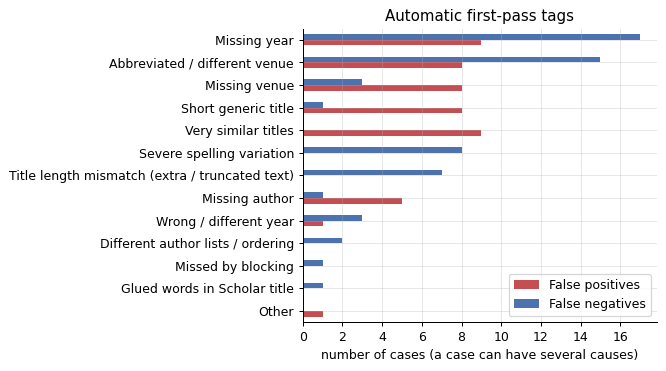

In [36]:
def cause_counts(df, col):
    return Counter(c for s in df[col] if s for c in s.split("; "))

has_manual = (errors_df.manual_cause != "").all()
cols = (["manual_cause"] if has_manual else []) + ["auto_causes"]
fig, axes = plt.subplots(1, len(cols), figsize=(7.5 * len(cols), 4.2))
axes = np.atleast_1d(axes)
for a, col in zip(axes, cols):
    sub = errors_df
    cc = pd.DataFrame({"False positives": cause_counts(sub[sub.kind == "FP"], col),
                       "False negatives": cause_counts(sub[sub.kind == "FN"], col)}).fillna(0).astype(int)
    cc = cc.loc[cc.sum(1).sort_values().index]
    cc.plot(kind="barh", ax=a, color=["#C44E52", "#4C72B0"])
    a.set_title("Manual causes (Section 45), read by hand" if col == "manual_cause" else "Automatic first-pass tags")
    a.set_xlabel("number of cases (a case can have several causes)")
plt.tight_layout(); save_fig(fig, "error_causes"); plt.show()
if has_manual:
    print("Primary manual cause:")
    display(errors_df.assign(primary=errors_df.manual_cause.str.split("; ").str[0])
            .groupby(["kind", "primary"]).size().rename("cases").reset_index())


### 16.1 What the 40 errors show

**False positives come from titles that say too little.** All 20 false positives have a primary cause of *very similar titles* (12) or *short generic title* (8). The generic ones are recurring columns and front matter — *Editor's Notes*, *Guest editorial*, *Book Review Column*, *Reminiscences on Influential Papers*, *Chair's Message* — where the title identifies a *kind* of article, not one article. In five of them DBLP has no authors, so after renormalization the score rests on the title and the year alone. The "very similar titles" cases are a different kind of mistake: in 11 of the 20 false positives the two records share most of their authors, and the Scholar record is a related publication by the same group — a tutorial, a demo, a sister paper (*Mining Generalized Association Rules* vs *Mining Association Rules*) or the conference version of a journal paper. Title + author similarity cannot separate two papers by the same people on the same topic, and in 9 of the 20 the Scholar year is missing, which removes the one field that often would. Three false positives (*Diluting ACID*, *Domains, Relations and Religious Wars*, one *Book Review Column*) agree on title, venue and year and are probably **gaps in the gold mapping**, not matcher errors.

**False negatives come from noisy Scholar records.** 16 of the 20 false negatives involve *severe spelling variation* in the Scholar title: citation text glued to the title (*"Agrawal, R.; Srikant, R.: Fast Algorithms…"*), report or proceedings text appended, glued words (*"QuerySystem fortheWorld-Wide"*), typos (*Spatail*, *mutimedia*), abbreviations (*GiST* for *Generalized Search Trees*) and titles split across fields. The second pattern is *different author ordering* (8 cases): reversed name order (*"G Jim, H Pat"* for *J Gray, P Helland*), Chinese names written family-name first (*"LU Hongjun"* vs *H Lu* — identical title, but author similarity 0.17 pushes the score to 0.67, just under T = 0.69), and author lists that Scholar truncates or merges. Only one false negative was lost by blocking (a title with glued words that shared no blocking key). The automatic tag *abbreviated / different venue* fires on 23 of the 40 cases but is **never the real cause**: validation gave the venue a weight of 0, so the venue cannot change any score — the noisy Scholar venues are exactly why it was switched off. **Possible fixes:** strip citation prefixes and appended report text before comparing titles, compare author names independent of first/last-name order, add a penalty for very short titles, and treat "same authors + similar title + missing year" as *manual review* rather than a match.

## 17. Scalability experiments (Section 43)

The full pipeline (blocking → features → weighted score → threshold) is re-run on 10 %, 25 %, 50 %, 75 % and 100 % of Scholar (reproducible random samples). Precision / recall / F1 are reported on the DBLP test split; blocking recall uses all gold pairs whose Scholar record is in the sample.

In [37]:
scal_rows = []
perm_s = np.random.default_rng(SEED).permutation(N_S)
for frac in [0.10, 0.25, 0.50, 0.75, 1.00]:
    s_rows = np.sort(perm_s[: int(round(frac * N_S))])
    t0 = time.time(); keys, _, _ = run_blocking(s_rows); t_block = time.time() - t0
    t0 = time.time()
    F = compute_features(*keys_to_pairs(keys))
    F["title_combined"] = ALPHA * F.title_edit + (1 - ALPHA) * F.title_jac
    F["score"] = weighted_score(F, W, AUTHOR_COL, VENUE_COL)
    t_match = time.time() - t0
    in_sample = np.isin(GOLD_KEYS % N_S, s_rows)
    g_keys = GOLD_KEYS[in_sample]
    is_test = dblp.split.to_numpy()[keys // N_S] == "test"
    g_test = g_keys[dblp.split.to_numpy()[g_keys // N_S] == "test"]
    pred_keys = keys[(F.score.to_numpy() >= THRESHOLD) & is_test]
    tp = int(np.isin(pred_keys, g_test).sum()); p = tp / max(len(pred_keys), 1); r = tp / max(len(g_test), 1)
    cart = N_D * len(s_rows)
    scal_rows.append({"scholar_fraction": f"{int(frac*100)}%", "scholar_records": len(s_rows), "dblp_records": N_D,
                      "cartesian_pairs": cart, "candidate_pairs": len(keys), "blocking_time_s": t_block,
                      "matching_time_s": t_match, "reduction_ratio": 1 - len(keys) / cart,
                      "blocking_recall": np.isin(g_keys, keys).mean(), "precision": p, "recall": r,
                      "f1": 2 * p * r / (p + r) if p + r else 0,
                      "est_bruteforce_python_h": cart * PY_SEC_PER_PAIR / 3600})
    print(f"{int(frac*100):>3}% done", end=" | ")
scal_df = pd.DataFrame(scal_rows)
scal_df.to_csv(f"{OUT_DIR}/scalability.csv", index=False)
print()
scal_df.style.format({"cartesian_pairs": "{:,}", "candidate_pairs": "{:,}", "blocking_time_s": "{:.2f}", "matching_time_s": "{:.2f}",
                      "reduction_ratio": "{:.5f}", "blocking_recall": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}",
                      "f1": "{:.4f}", "est_bruteforce_python_h": "{:.1f}"})

 10% done |  25% done |  50% done |  75% done | 100% done | 


,scholar_fraction,scholar_records,dblp_records,cartesian_pairs,candidate_pairs,blocking_time_s,matching_time_s,reduction_ratio,blocking_recall,precision,recall,f1,est_bruteforce_python_h
0,10%,6426,2616,"16,810,416","46,934",0.63,0.83,0.99721,0.9856,0.8448,0.8829,0.8634,9.5
1,25%,16066,2616,"42,028,656","114,987",1.93,1.59,0.99726,0.9887,0.8700,0.9198,0.8942,23.7
2,50%,32132,2616,"84,057,312","232,084",2.91,3.34,0.99724,0.9842,0.8789,0.9072,0.8928,47.3
3,75%,48197,2616,"126,083,352","346,065",4.36,5.17,0.99726,0.9805,0.8762,0.9045,0.8902,71.0
4,100%,64263,2616,"168,112,008","462,813",6.01,6.70,0.99725,0.9807,0.8726,0.8937,0.8831,94.6


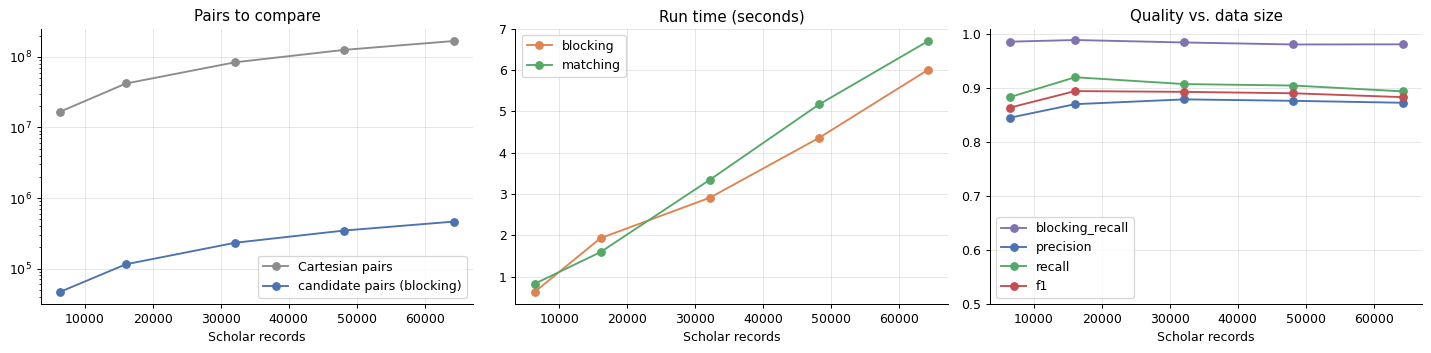

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
xs = scal_df.scholar_records
ax[0].plot(xs, scal_df.cartesian_pairs, "o-", label="Cartesian pairs", color="#8C8C8C")
ax[0].plot(xs, scal_df.candidate_pairs, "o-", label="candidate pairs (blocking)", color="#4C72B0")
ax[0].set_yscale("log"); ax[0].set_title("Pairs to compare"); ax[0].set_xlabel("Scholar records"); ax[0].legend()
ax[1].plot(xs, scal_df.blocking_time_s, "o-", label="blocking", color="#DD8452")
ax[1].plot(xs, scal_df.matching_time_s, "o-", label="matching", color="#55A868")
ax[1].set_title("Run time (seconds)"); ax[1].set_xlabel("Scholar records"); ax[1].legend()
for m, c in [("blocking_recall", "#8172B2"), ("precision", "#4C72B0"), ("recall", "#55A868"), ("f1", "#C44E52")]:
    ax[2].plot(xs, scal_df[m], "o-", label=m, color=c)
ax[2].set_ylim(0.5, 1.01); ax[2].set_title("Quality vs. data size"); ax[2].set_xlabel("Scholar records"); ax[2].legend(loc="lower left")
plt.tight_layout(); save_fig(fig, "scalability"); plt.show()

## 18. Save everything to the relational database (SQLite)

Schema follows Section 9 (updated): `MATCH_RESULT` also stores the split, the confidence band and the ML probability, and a new `REVIEW` table stores human decisions. Student 2 owns the database design, so align the table and column names with theirs if they differ.

In [39]:
con = sqlite3.connect(DB_PATH, check_same_thread=False)
con.executescript("""
DROP TABLE IF EXISTS DBLP_RECORD; DROP TABLE IF EXISTS SCHOLAR_RECORD; DROP TABLE IF EXISTS GOLD_MATCH;
DROP TABLE IF EXISTS CANDIDATE_PAIR; DROP TABLE IF EXISTS MATCH_RESULT; DROP TABLE IF EXISTS EXPERIMENT;
CREATE TABLE DBLP_RECORD   (record_id TEXT PRIMARY KEY, title TEXT, authors TEXT, venue TEXT, year INTEGER, split TEXT);
CREATE TABLE SCHOLAR_RECORD(record_id TEXT PRIMARY KEY, title TEXT, authors TEXT, venue TEXT, year INTEGER);
CREATE TABLE GOLD_MATCH    (dblp_id TEXT REFERENCES DBLP_RECORD, scholar_id TEXT REFERENCES SCHOLAR_RECORD, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE CANDIDATE_PAIR(dblp_id TEXT, scholar_id TEXT, blocking_rule TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE MATCH_RESULT  (dblp_id TEXT, scholar_id TEXT, title_similarity REAL, author_similarity REAL,
                            venue_similarity REAL, year_similarity REAL, overall_similarity REAL, lr_probability REAL,
                            prediction INTEGER, band TEXT, split TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE IF NOT EXISTS REVIEW (dblp_id TEXT, scholar_id TEXT, decision TEXT CHECK (decision IN ('Confirm Match','Reject Match','Needs Review')),
                            note TEXT, reviewer TEXT, reviewed_at TEXT, PRIMARY KEY (dblp_id, scholar_id));
CREATE TABLE EXPERIMENT    (name TEXT PRIMARY KEY, result_json TEXT, created_at TEXT);
""")
cols = ["id", "title", "authors", "venue", "year"]
dblp[cols + ["split"]].rename(columns={"id": "record_id"}).to_sql("DBLP_RECORD", con, if_exists="append", index=False)
scholar[cols].rename(columns={"id": "record_id"}).to_sql("SCHOLAR_RECORD", con, if_exists="append", index=False)
gold_df[["dblp_id", "scholar_id"]].to_sql("GOLD_MATCH", con, if_exists="append", index=False)

rule_names = list(PASS_KEYS)
member = np.column_stack([np.isin(CAND_KEYS, PASS_KEYS[n]) for n in rule_names])
rules = np.array([",".join(n for n, m in zip(rule_names, row) if m) for row in member])
DBLP_IDS, SCH_IDS = dblp.id.to_numpy(), scholar.id.to_numpy()
pd.DataFrame({"dblp_id": DBLP_IDS[di_c], "scholar_id": SCH_IDS[si_c], "blocking_rule": rules}).to_sql(
    "CANDIDATE_PAIR", con, if_exists="append", index=False)
FEAT["dblp_id"] = DBLP_IDS[FEAT.di]; FEAT["scholar_id"] = SCH_IDS[FEAT.si]
pd.DataFrame({"dblp_id": FEAT.dblp_id, "scholar_id": FEAT.scholar_id, "title_similarity": FEAT.title_combined,
              "author_similarity": FEAT[AUTHOR_COL], "venue_similarity": FEAT[VENUE_COL], "year_similarity": FEAT.year,
              "overall_similarity": FEAT.score, "lr_probability": FEAT.lr_prob,
              "prediction": (FEAT.score >= THRESHOLD).astype(int), "band": FEAT.band, "split": FEAT.split}).to_sql(
    "MATCH_RESULT", con, if_exists="append", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_match_band ON MATCH_RESULT(band, overall_similarity)")
con.execute("CREATE INDEX IF NOT EXISTS idx_match_dblp ON MATCH_RESULT(dblp_id)")

# restore earlier review decisions from Drive (they survive Colab restarts)
if os.path.exists(REVIEW_CSV):
    old = pd.read_csv(REVIEW_CSV).drop_duplicates(["dblp_id", "scholar_id"], keep="last")
    con.executemany("INSERT OR REPLACE INTO REVIEW VALUES (?,?,?,?,?,?)", old[["dblp_id", "scholar_id", "decision", "note", "reviewer", "reviewed_at"]].fillna("").values.tolist())

SUMMARY = {
    "dataset": {"dblp": N_D, "scholar": N_S, "gold": len(GOLD), "cartesian_pairs": P_ALL},
    "blocking": {"candidates": int(len(CAND_KEYS)), "reduction_ratio": BM["reduction_ratio"], "blocking_recall": BM["blocking_recall"],
                 "time_s": BLOCKING_TIME},
    "chosen": {"alpha": ALPHA, "weights_title_author_venue_year": list(map(float, W)), "author_measure": AUTHOR_COL,
               "venue_measure": VENUE_COL, "threshold": THRESHOLD, "band_high": T_HIGH, "band_low": T_LOW},
    "test_results": comparison_df.drop(columns=["pairs scored"]).to_dict(orient="records"),
}
import platform, sklearn, scipy, rapidfuzz
SUMMARY["environment"] = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                          "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "rapidfuzz": rapidfuzz.__version__}
con.execute("INSERT OR REPLACE INTO EXPERIMENT VALUES (?,?,datetime('now'))", ("final_run", json.dumps(SUMMARY, default=float)))
con.commit()
print(pd.read_sql("SELECT name AS tbl FROM sqlite_master WHERE type='table'", con).assign(
    rows=lambda x: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in x.tbl]))
with open(f"{OUT_DIR}/summary.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, indent=2, default=float)
if IN_COLAB:
    shutil.copy(DB_PATH, f"{OUT_DIR}/entityguard.db")
    print("database copied to Drive:", f"{OUT_DIR}/entityguard.db")
# slim copy for the web app (records, gold, MATCH_RESULT with score >= 0.40, experiment) — small enough for GitHub
from src.api.store import export_app_db
APP_DB = f"{OUT_DIR}/entityguard_app.db"
print(f"app database: {APP_DB} ({export_app_db(DB_PATH, APP_DB, min_score=0.40):.1f} MB)")


              tbl    rows
0          REVIEW      90
1     DBLP_RECORD    2616
2  SCHOLAR_RECORD   64263
3      GOLD_MATCH    5347
4  CANDIDATE_PAIR  462813
5    MATCH_RESULT  462813
6      EXPERIMENT       1
app database: c:\Users\Acer\Documents\GitHub\EntityGuard/outputs/entityguard_app.db (17.2 MB)


## 19. Web application — human review interface + dashboard (Sections 40, 46, 47)

The app is **standalone**: `src/api/app.py` (FastAPI, all 8 routes of Section 47) with the Gradio interface mounted at `/ui` (`src/api/ui.py`). It loads only saved artifacts — `outputs/entityguard_app.db`, `outputs/summary.json`, `outputs/lr_model.joblib` and `outputs/human_reviews.csv` — so it no longer depends on this notebook's variables.

Pages (Section 46): **Dataset Statistics · Blocking Configuration · Run Matching · Candidate Pairs · Review Pair · Evaluation · Performance Dashboard**. *Review Pair* shows the DBLP and Scholar records side by side with every field similarity, the overall score, the confidence band and the LR probability, plus **Confirm Match / Reject Match / Needs Review**. Decisions are saved to `human_reviews.csv`.

Run it locally from the repo root with `uvicorn src.api.app:api --reload` and open http://localhost:8000/ui. In Colab, the next cell prints a public `gradio.live` link.

In [40]:
from src.api.app import create_app
from src.api.ui import build_ui

api = create_app(out_dir=OUT_DIR)            # FastAPI + Gradio UI, built only from the saved artifacts
STORE = api.state.store
print("app loaded:", STORE.n_dblp, "DBLP |", STORE.n_scholar, "Scholar |",
      int(STORE.sql("SELECT COUNT(*) n FROM MATCH_RESULT").n[0]), "stored pairs | reviews:", STORE.reviews()[1])

# the app reproduces the notebook's M4 test result from the database alone
_m = STORE.run_matching(THRESHOLD)["test"]
_m4 = comparison_df[comparison_df.method.str.startswith("M4")].iloc[0]
assert (_m["TP"], _m["FP"], _m["FN"]) == (int(_m4.TP), int(_m4.FP), int(_m4.FN))
print("✅ app reproduces M4 on test:", {k: round(v, 4) if isinstance(v, float) else v for k, v in _m.items()})

LAUNCH_APP = IN_COLAB or os.environ.get("EG_LAUNCH") == "1"
if LAUNCH_APP:
    build_ui(STORE).launch(share=IN_COLAB, debug=False)     # public gradio.live link in Colab
else:
    print("UI built (launch skipped outside Colab; locally run: uvicorn src.api.app:api --reload)")


app loaded: 2616 DBLP | 64263 Scholar | 23754 stored pairs | reviews: {'reviews': 90, 'Confirm Match': 47, 'Reject Match': 43, 'Needs Review': 0, 'agreement_with_gold': 0.8111111111111111}
✅ app reproduces M4 on test: {'TP': 925, 'FP': 135, 'FN': 110, 'precision': 0.8726, 'recall': 0.8937, 'f1': 0.8831}
UI built (launch skipped outside Colab; locally run: uvicorn src.api.app:api --reload)


## 20. REST API server (Section 47) and automated tests

`RUN_API = True` starts the FastAPI server (with the interface at `/ui` and API docs at `/docs`) in a background thread. In Colab the printed link uses Colab's proxy, so it works only while this notebook is open. The second cell runs the project's whole test suite (`tests/`, including the API tests).

In [41]:
RUN_API = False   # set True to start the API server

if RUN_API:
    import threading, uvicorn
    threading.Thread(target=lambda: uvicorn.run(api, host="0.0.0.0", port=8000, log_level="warning"), daemon=True).start()
    time.sleep(3)
    if IN_COLAB:
        from google.colab.output import eval_js
        print("API docs :", eval_js("google.colab.kernel.proxyPort(8000)") + "docs")
        print("Web app  :", eval_js("google.colab.kernel.proxyPort(8000)") + "ui")
    else:
        print("API running at http://localhost:8000/docs  ·  interface at http://localhost:8000/ui")


In [42]:
import subprocess
_r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], cwd=REPO_DIR, capture_output=True, text=True)
print(_r.stdout[-1500:] or _r.stderr[-1500:])
assert _r.returncode == 0, "some tests failed"


...................................................................      [100%]
67 passed in 11.46s



### 20.1 Optional: review pairs inside the notebook

The web app is the main review tool. This cell offers a quick text alternative (`RUN_MANUAL_REVIEW = True`) and always reports the agreement of all saved review decisions with the gold mapping.

In [43]:
from datetime import datetime

RUN_MANUAL_REVIEW = False   # True = label 50 borderline pairs here by typing y / n (interactive)

if RUN_MANUAL_REVIEW:
    # 1. Grab 50 unreviewed borderline pairs from the Manual review band
    done = set(con.execute("SELECT dblp_id, scholar_id FROM REVIEW").fetchall())
    pool = FEAT[FEAT["band"] == "Manual review"].copy()
    pool["uncertainty"] = (pool["score"] - THRESHOLD).abs()
    pool = pool.sort_values("uncertainty")
    pool = pool[~pool[["dblp_id", "scholar_id"]].apply(tuple, axis=1).isin(done)].head(50)

    print(f"Loaded {len(pool)} borderline pairs for review.\nType 'y' for Confirm Match, 'n' for Reject Match, or 'q' to stop early:\n")

    count = 0
    for idx, row in pool.iterrows():
        count += 1
        d = dblp.iloc[int(row["di"])]
        s = scholar.iloc[int(row["si"])]
        print("=" * 70)
        print(f"[{count}/50] Score: {row['score']:.3f} | DBLP: {d['title']} ({d['authors']}, {d['year']})")
        print(f"                        | SCHL: {s['title']} ({s['authors']}, {s['year']})")
        ans = input("Match? (y/n/q): ").strip().lower()
        if ans == 'q':
            break
        decision = "Confirm Match" if ans == 'y' else "Reject Match"
        con.execute("INSERT OR REPLACE INTO REVIEW (dblp_id, scholar_id, decision, note, reviewer, reviewed_at) "
                    "VALUES (?, ?, ?, ?, ?, ?)",
                    (row["dblp_id"], row["scholar_id"], decision, "", "student3", datetime.now().isoformat()))

    con.commit()
    pd.read_sql("SELECT * FROM REVIEW", con).to_csv(REVIEW_CSV, index=False)

# agreement of the human decisions with the gold mapping (evaluation only)
reviews_df = pd.read_sql("SELECT * FROM REVIEW WHERE decision != 'Needs Review'", con)
human_match = (reviews_df.decision == "Confirm Match").to_numpy()
in_gold = np.array([(d, s) in GOLD for d, s in zip(reviews_df.dblp_id, reviews_df.scholar_id)])
REVIEW_AGREEMENT = float((human_match == in_gold).mean()) if len(reviews_df) else float("nan")
print(f"{len(reviews_df)} reviewed pairs | agreement with the gold mapping: {REVIEW_AGREEMENT:.1%}")


90 reviewed pairs | agreement with the gold mapping: 81.1%


## 21. Results summary (copy into the report)

In [44]:
best_row = comparison_df.loc[comparison_df.f1.idxmax()]
m4row = comparison_df[comparison_df.method.str.startswith("M4")].iloc[0]
b1row = comparison_df.iloc[0]
lines = [
    f"Search space: {P_ALL:,} cross-source pairs ({N_D:,} DBLP × {N_S:,} Scholar), {len(GOLD):,} gold matches.",
    f"Multi-pass blocking produced {len(CAND_KEYS):,} candidates: reduction ratio {BM['reduction_ratio']:.4%}, "
    f"blocking recall {BM['blocking_recall']:.2%}, in {BLOCKING_TIME:.1f}s.",
    f"Year blocking alone would give {year_cands:,} pairs with only {year_hits/len(GOLD):.1%} recall (54% of Scholar has no year).",
    f"Validation chose α={ALPHA}, weights (title, author, venue, year)={W}, author measure '{AUTHOR_COL}', venue measure '{VENUE_COL}', T={THRESHOLD}.",
    f"Test F1: exact-title baseline {b1row.f1:.3f} → weighted + blocking {m4row.f1:.3f} "
    f"(precision {m4row.precision:.3f}, recall {m4row.recall:.3f}).",
    f"Best method on test: {' '.join(best_row.method.split())} with F1 {best_row.f1:.3f}.",
    f"Confidence bands: S ≥ {T_HIGH} high confidence, {T_LOW}–{T_HIGH} manual review, < {T_LOW} likely non-match.",
    f"A pure-Python scorer would need ≈ {PY_SEC_PER_PAIR*P_ALL/3600:.1f} h for all pairs; blocking + matching took "
    f"{BLOCKING_TIME + MATCH_TIME_FEATURES:.0f}s.",
]
_ex = s1_settings_df.iloc[0]; _tu = s1_settings_df.iloc[-1]
lines.append(f"Student 1's example settings (α=0.4, weights 0.50/0.30/0.10/0.10, token-Jaccard authors) reach test F1 "
             f"{_ex['test F1']:.3f} in the full pipeline (F1 {_ex['Student 1 sample F1']:.3f} on Student 1's 50/50 sample); "
             f"the setting tuned on validation reaches {_tu['test F1']:.3f}.")
if RUN_BRUTE_FORCE:
    m3row = comparison_df[comparison_df.method.str.startswith("M3")].iloc[0]
    lines.append(f"Without blocking (M3) the same weighted score reached F1 {m3row.f1:.3f} (recall {m3row.recall:.3f}); "
                 f"with blocking (M4) only {len(CAND_KEYS)/P_ALL:.2%} of the pairs are scored and recall changes by "
                 f"{(m4row.recall - m3row.recall)*100:+.1f} points.")
print("\n".join("• " + l for l in lines))
with open(f"{OUT_DIR}/results_summary.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print("\nAll outputs saved in:", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

• Search space: 168,112,008 cross-source pairs (2,616 DBLP × 64,263 Scholar), 5,347 gold matches.
• Multi-pass blocking produced 462,813 candidates: reduction ratio 99.7247%, blocking recall 98.07%, in 6.4s.
• Year blocking alone would give 4,267,488 pairs with only 45.3% recall (54% of Scholar has no year).
• Validation chose α=0.6, weights (title, author, venue, year)=(0.45, 0.3, 0.0, 0.25), author measure 'author_best', venue measure 'venue_tri', T=0.69.
• Test F1: exact-title baseline 0.635 → weighted + blocking 0.883 (precision 0.873, recall 0.894).
• Best method on test: M5b Decision Tree + blocking with F1 0.901.
• Confidence bands: S ≥ 0.95 high confidence, 0.49–0.95 manual review, < 0.49 likely non-match.
• A pure-Python scorer would need ≈ 94.6 h for all pairs; blocking + matching took 14s.
• Student 1's example settings (α=0.4, weights 0.50/0.30/0.10/0.10, token-Jaccard authors) reach test F1 0.833 in the full pipeline (F1 0.948 on Student 1's 50/50 sample); the setting tune

## 22. What to do next (Student 3 checklist)

1. **Error analysis:** read the 40 cases in `outputs/error_analysis_40_cases.csv`, fill in `manual_cause` with the Section 45 categories, and write 1–2 paragraphs on the patterns. Labels survive a re-run for cases that are sampled again.
2. **Blocking:** when Student 2's `src/blocking/` exists, replace the reference `run_blocking` in Section 9 and re-run.
3. **Report:** use `outputs/results_summary.txt`, `outputs/summary.json`, the CSV tables and the PNG plots in `outputs/`.
